# Thrombectomy use and variation in transfer for thrombectomy

This notebook describes how often patients with stroke receive thrombectomy (mechanical removal of a blood clot from a brain artery, MT), using national stroke audit data (SSNAP, via the SAMueL-3 project). It focuses on patients who first arrive at a hospital that does not perform thrombectomy and so must be transferred to another hospital for it. It combines descriptive statistics with a machine learning model of which patients receive thrombectomy.

**Aims**

1. Describe how often patients with ischaemic stroke and NIHSS > 10 receive thrombectomy, by the type of hospital first attended and by whether they also receive thrombolysis.
2. Compare patients treated with thrombectomy after transfer with those treated at the hospital they first attended: time from arrival to thrombectomy, and patient characteristics.
3. Describe how much non-thrombectomy hospitals vary in giving thrombolysis and in transferring patients for thrombectomy, and whether differences in thrombolysis explain differences in transfer.
4. Establish whether stroke teams differ in *how many* patients they send for thrombectomy, in *which* patients they send, or both.
5. Examine how teams' thrombectomy rates relate to the thrombectomy unit they transfer to, and to that unit's thrombectomy rate for its own patients.

**Population**

Stroke admissions recorded in SSNAP in 2024–2025. Most analyses use patients with **ischaemic stroke and NIHSS > 10** (27,147 patients), as those most likely to be suitable for thrombectomy. Particular sections use these subsets:
- **Thrombectomy within 12 hours:** patients who received thrombectomy within 12 hours of arrival (5,287), for the comparison of times and patient characteristics.
- **Non-thrombectomy hospitals:** patients who first attended one of 87 hospitals that do not perform thrombectomy (18,296 with ischaemic stroke and NIHSS > 10). The hospital-level thrombolysis and transfer rates also use all stroke admissions to these hospitals (110,090).
- **Thrombectomy units:** patients of non-thrombectomy hospitals whose team has a recorded thrombectomy unit that it transfers to (18,189 patients, 86 teams, 21 units), compared with patients who first attended those units.

For patients who first attend a non-thrombectomy hospital, receiving thrombectomy is used as the measure of transfer for thrombectomy (96% of these thrombectomies had a transfer recorded). In this notebook a "stroke team" is the stroke service at one hospital.

**Key terms**

- **NIHSS** (National Institutes of Health Stroke Scale): stroke severity, from 0 to 42; higher is more severe.
- **mRS** (modified Rankin Scale): disability, from 0 (no symptoms) to 5 (severe disability); 6 = death. "Prior mRS" is disability before the stroke.
- **Median and IQR:** the middle value, and the interquartile range (the range covering the middle half of patients).
- **p-value:** the probability of seeing a difference at least this large if there were really no difference. Values below 0.05 are conventionally called statistically significant. In large datasets even very small differences can have small p-values.
- **Odds ratio:** how much the odds of an outcome are multiplied by; 1 = no change, 2 = doubled, 0.5 = halved.
- **Correlation:** how closely two measures rise and fall together, from −1 to +1 (0 = no relationship). **R²** is the proportion of the variation in one measure that is accounted for by a straight-line relationship with another (0 to 1).
- **Machine learning model (XGBoost):** a method that learns to predict an outcome (here, thrombectomy) from patient and hospital information by combining many small decision trees (simple sets of yes/no rules).
- **SHAP:** a method that shows how much each piece of information pushed an individual patient's predicted chance of thrombectomy up or down.

**Contents**

1. **Load data and overall thrombectomy rates.**
2. **Patients receiving thrombectomy within 12 hours of arrival:** times to thrombectomy, and patient characteristics, by type of hospital first attended.
3. **Thrombolysis and transfer for thrombectomy by non-thrombectomy hospital:** variation between hospitals, and whether thrombolysis explains variation in transfer.
4. **Do stroke teams differ in which patients they select for thrombectomy?** A machine learning model of thrombectomy using patient characteristics, stroke team and thrombectomy unit, used to compare teams on the same patients.
5. **Thrombectomy units and variation between referring teams.**
6. **Conclusions.**

Each code cell has an explanation of its method above it and a commentary on its results below it. Options (`use_anon_teams`, `retune_model`) are set in the data-loading cell. Tables and figures are saved to `./output/`.

## Load data and overall thrombectomy rates

**What this cell does:** Loads the Python software libraries used for handling data, calculations and charts.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

**Results:** Nothing is shown; this cell only prepares the software.

**What this cell does:** Sets two options and loads the data. `use_anon_teams` chooses whether hospitals are identified by anonymised three-letter codes (True, as now) or by real names (False). `retune_model` chooses whether the machine learning model later in the notebook has its settings re-optimised (True, takes about 5 minutes) or re-uses the settings saved from the last optimisation (False). The cell then loads the SSNAP data, keeps admissions from 2024 and 2025, and calculates the proportion of all these stroke admissions who received thrombectomy.

In [2]:
# Settings
# use_anon_teams: load data with anonymised stroke team names (True) or real names (False)
# retune_model: re-tune the XGBoost hyperparameters with Optuna (~5 min) and save them to
#   output/xgb_tuning.json (True), or load the previously saved hyperparameters (False)
use_anon_teams = True
retune_model = False

if use_anon_teams:
    all_data = pd.read_csv("../data/sam3/cleaned_data_anon_teams.csv", low_memory=False)
else:
    all_data = pd.read_csv("../data/sam3/cleaned_data.csv", low_memory=False)

# Select years to include (inclusive)
min_year = 2024
max_year = 2025

# Get data for selected years
mask = (all_data['year'] >= min_year) & (all_data['year'] <= max_year)
data_filtered = all_data[mask]

# Get the avergae thrombectomy of all patients
data_filtered['thrombectomy'].mean()


np.float64(0.04623897895562257)

**Results:** 4.6% of all stroke admissions in 2024–2025 received thrombectomy.

**What this cell does:** Keeps only patients with ischaemic stroke (stroke caused by a blocked artery, rather than bleeding), and recalculates the proportion receiving thrombectomy.

In [3]:
# Limit to infarction == 1
data_filtered = data_filtered[data_filtered['infarction'] == 1]
data_filtered['thrombectomy'].mean()

np.float64(0.0533426491137751)

**Results:** 5.3% of patients with ischaemic stroke received thrombectomy.

**What this cell does:** Keeps only patients with a more severe stroke: NIHSS above 10. These patients are the most likely to have a blockage of a large artery that is suitable for thrombectomy, and they are the main population for the rest of the notebook.

In [4]:
# Limit to stroke_severity > 10
data_filtered = data_filtered[data_filtered['stroke_severity'] > 10]
data_filtered['thrombectomy'].mean()

np.float64(0.20466349872914133)

**Results:** 20.5% of the 27,147 patients with ischaemic stroke and NIHSS > 10 received thrombectomy.

**What this cell does:** Splits these patients by the type of hospital they first arrived at: a thrombectomy centre (which performs thrombectomy itself) or a non-thrombectomy centre (which must transfer patients elsewhere for it), and calculates the proportion receiving thrombectomy in each group (0 = non-thrombectomy centre, 1 = thrombectomy centre).

In [5]:
# Get proportion thrombectomy by thrombectomy_centre
proportion_thrombectomy = data_filtered.groupby('thrombectomy_centre')['thrombectomy'].mean()
proportion_thrombectomy


thrombectomy_centre
0    0.177634
1    0.260536
Name: thrombectomy, dtype: float64

**Results:** Patients who first arrived at a thrombectomy centre were more likely to receive thrombectomy: 26.1%, compared with 17.8% of those who first arrived at a non-thrombectomy centre.

**What this cell does:** Splits each group further by whether the patient also received thrombolysis (a clot-dissolving drug), giving the number of patients and the proportion receiving thrombectomy in each of the four groups.

In [6]:
df_split = data_filtered.groupby(
    ["thrombectomy_centre", "thrombolysis"]
).agg({"thrombectomy": ["mean", "count"]})

# Make df_split index more readable
df_split.index = df_split.index.set_names(["Thrombectomy Centre", "Thrombolysis"])

# Unmerge index
df_split = df_split.reset_index()

df_split


Thrombectomy Centre Thrombolysis thrombectomy       
                                           mean  count
0                   0            0     0.122092  12507
1                   0            1     0.297633   5789
2                   1            0     0.203890   6273
3                   1            1     0.398371   2578

**Results:** Proportion receiving thrombectomy (and number of patients) by first-attended centre type and thrombolysis:

| First attended | No thrombolysis | Thrombolysis |
|---|---|---|
| Non-thrombectomy centre | 12.2% (n = 12,507) | 29.8% (n = 5,789) |
| Thrombectomy centre | 20.4% (n = 6,273) | 39.8% (n = 2,578) |

Thrombectomy rates are higher at thrombectomy centres both with and without thrombolysis. Within each type of centre, patients who received thrombolysis were about two to two-and-a-half times as likely to also receive thrombectomy. This probably reflects patients arriving earlier and being more suitable for reperfusion treatment, not an effect of thrombolysis itself. The proportion receiving thrombolysis was similar: 31.6% at non-thrombectomy centres and 29.1% at thrombectomy centres. In total, all 27,147 patients have a known type of first hospital.

## Patients receiving thrombectomy within 12 hours of arrival

**What this cell does:** Keeps only patients who received thrombectomy within 12 hours (720 minutes) of arriving at their first hospital. Patients who did not receive thrombectomy have no arrival-to-thrombectomy time, so they are excluded automatically: the cells below describe **thrombectomy patients only**.

In [7]:
# Clip arrival-to-thrombectomy times at 12 hours
mask = data_filtered['arrival_to_thrombectomy_time'] <= 720
data_filtered_12hr = data_filtered[mask]

**Results:** No output is shown. 5,287 thrombectomy patients remain: 3,073 who first arrived at a non-thrombectomy centre and 2,214 who first arrived at a thrombectomy centre (see the counts below).

**What this cell does:** Summarises the time from arrival at the first hospital to thrombectomy, in minutes, for patients who first arrived at a non-thrombectomy centre (column 0) and at a thrombectomy centre (column 1). The table gives the number of patients (count), the mean, the standard deviation (std, a measure of spread), and the minimum, quartiles (25%, 50% = median, 75%) and maximum.

In [8]:
data_filtered_12hr.groupby(
    ["thrombectomy_centre"])['arrival_to_thrombectomy_time'].describe().T

thrombectomy_centre,0,1
count,3073.000000,2214.000000
mean,246.262935,150.522132
std,99.859412,92.896233
min,0.000000,0.000000
25%,181.000000,97.000000
50%,221.000000,127.000000
75%,284.000000,174.000000
max,720.000000,720.000000


**Results:** Patients who first arrived at a non-thrombectomy centre waited much longer from arrival to thrombectomy: median 221 minutes (IQR 181–284) versus 127 minutes (IQR 97–174) for those who arrived at a thrombectomy centre, about 1.5 hours longer. Mean times were 246 versus 151 minutes. The difference is consistent with the time taken to transfer patients between hospitals. The maximum of 720 minutes in both groups reflects the 12-hour limit applied above.

**What this cell does:** Repeats the summary of time to thrombectomy, split further by whether patients also received thrombolysis, to see whether thrombolysis is linked with a different time to thrombectomy.

In [9]:
data_filtered_12hr.groupby(
    ["thrombectomy_centre", "thrombolysis"])['arrival_to_thrombectomy_time'].describe().T

thrombectomy_centre            0                         1            
thrombolysis                   0            1            0           1
count                1428.000000  1645.000000  1236.000000  978.000000
mean                  258.436275   235.695441   154.633495  145.326176
std                   105.855315    93.096033   100.637744   81.830560
min                    90.000000     0.000000     0.000000    0.000000
25%                   188.000000   177.000000    97.000000   97.000000
50%                   231.000000   214.000000   127.000000  126.500000
75%                   303.000000   270.000000   176.250000  167.750000
max                   720.000000   718.000000   709.000000  720.000000

**Results:** Thrombolysis makes little difference to time to thrombectomy within each type of hospital. Non-thrombectomy centre: median 231 minutes without thrombolysis versus 214 minutes with it. Thrombectomy centre: 127 versus 126.5 minutes. The type of hospital first attended is what drives the difference in time.

### Characteristics of thrombectomy patients by type of first hospital

Compares the characteristics of patients who received thrombectomy (within 12 hours of arrival), according to whether they first arrived at a thrombectomy centre or at a non-thrombectomy centre (and so were almost always transferred).

**What this cell does:** Selects the thrombectomy patients and prepares some characteristics for comparison. Ethnicity, prior mRS and mRS at discharge are each split into one yes/no column per category (for example, "prior mRS 2: yes or no"), so that the proportion of patients in each category can be compared. Missing discharge mRS is kept as missing. It then counts the patients in each group.

In [10]:
from scipy import stats

# Thrombectomy patients only, split by whether first attended a thrombectomy centre
thrombectomy_patients = data_filtered_12hr[
    (data_filtered_12hr['thrombectomy'] == 1) & (data_filtered_12hr['thrombectomy_centre'].notna())
].copy()

# One-hot encode categorical fields so each level can be compared as a proportion
thrombectomy_patients = pd.concat([
    thrombectomy_patients,
    pd.get_dummies(thrombectomy_patients['ethnicity'], prefix='ethnicity', dtype=float),
    pd.get_dummies(thrombectomy_patients['prior_disability'], prefix='prior_mrs', dtype=float),
    # Keep missing discharge mRS as missing (rather than 0 in every dummy column)
    pd.get_dummies(thrombectomy_patients['discharge_disability'], prefix='discharge_mrs', dtype=float)
      .where(thrombectomy_patients['discharge_disability'].notna()),
], axis=1)

group_labels = {0: 'Non-thrombectomy centre', 1: 'Thrombectomy centre'}
thrombectomy_patients['first_centre'] = (
    thrombectomy_patients['thrombectomy_centre'].astype(int).map(group_labels))

thrombectomy_patients['first_centre'].value_counts()

first_centre
Non-thrombectomy centre    3073
Thrombectomy centre        2214
Name: count, dtype: int64

**Results:** 5,287 thrombectomy patients: 3,073 (58%) first arrived at a non-thrombectomy centre and 2,214 (42%) at a thrombectomy centre.

### Comparing groups: the standardised mean difference (SMD)

To compare the two groups on each characteristic we use the **standardised mean difference (SMD)**. It expresses the difference between the groups as a fraction of the usual spread of that characteristic between patients (its standard deviation). This puts characteristics measured in different units (years, minutes, percentages) on the same scale.

- An SMD of 0 means no difference. Positive values mean the characteristic is higher, or more common, in patients who first arrived at a thrombectomy centre; negative values mean it is higher in those who first arrived at a non-thrombectomy centre.
- An SMD beyond ±0.1 is commonly taken to indicate a meaningful difference between groups.
- Unlike a p-value, the SMD does not shrink as the number of patients grows, so it is a better guide to whether a difference matters.

**Calculation (for reference).** With $\bar{x}$ the group mean and $s^2$ the group variance (spread):

$$
\text{SMD} = \frac{\bar{x}_1 - \bar{x}_0}{\sqrt{\dfrac{s_1^2 + s_0^2}{2}}}
$$

where group 1 is patients who first arrived at a thrombectomy centre and group 0 those who first arrived at a non-thrombectomy centre. For yes/no characteristics the mean is the proportion $p$ with the characteristic, so the formula becomes

$$
\text{SMD} = \frac{p_1 - p_0}{\sqrt{\dfrac{p_1(1 - p_1) + p_0(1 - p_0)}{2}}}
$$

For example, Asian ethnicity: $p_1 = 96/2214 = 0.043$ and $p_0 = 119/3073 = 0.039$, so SMD $= 0.0046 / 0.198 = 0.02$.

For measurements (such as age, NIHSS and times) the table reports the median [IQR], but the SMD is based on means, so its size can differ from the difference in medians. Banded or ordered scores (age bands, prior mRS) are treated as numbers. Missing values are left out separately for each characteristic.

**What this cell does:** Builds a table comparing the two groups on each characteristic. For yes/no characteristics it gives % (number of patients); for measurements it gives median [IQR]. It also gives the number of patients with data in each group, the SMD, and a p-value (chi-square test for yes/no characteristics; Mann–Whitney U test, which compares medians, for measurements).

In [11]:
# Characteristics to compare: (variable, label, type) where type is 'binary' or 'continuous'
ethnicity_cols = sorted(c for c in thrombectomy_patients.columns if c.startswith('ethnicity_'))
prior_mrs_cols = sorted(c for c in thrombectomy_patients.columns if c.startswith('prior_mrs_'))
discharge_mrs_cols = sorted(c for c in thrombectomy_patients.columns if c.startswith('discharge_mrs_'))

variables = (
    [('age', 'Age (years, banded)', 'continuous'),
     ('male', 'Male', 'binary')]
    + [(c, f"Ethnicity: {c.replace('ethnicity_', '')}", 'binary') for c in ethnicity_cols]
    + [('stroke_severity', 'NIHSS on arrival', 'continuous'),
       ('lvo', 'Large vessel occlusion (where recorded)', 'binary'),
       ('prior_disability', 'Prior mRS', 'continuous')]
    + [(c, f"Prior mRS {c.replace('prior_mrs_', '')}", 'binary') for c in prior_mrs_cols]
    + [('congestive_heart_failure', 'Congestive heart failure', 'binary'),
       ('hypertension', 'Hypertension', 'binary'),
       ('atrial_fibrillation', 'Atrial fibrillation', 'binary'),
       ('diabetes', 'Diabetes', 'binary'),
       ('prior_stroke_tia', 'Prior stroke/TIA', 'binary'),
       ('afib_anticoagulant', 'AF on anticoagulant', 'binary'),
       ('onset_known', 'Onset time known', 'binary'),
       ('precise_onset_known', 'Precise onset known', 'binary'),
       ('onset_during_sleep', 'Onset during sleep', 'binary'),
       ('arrive_by_ambulance', 'Arrived by ambulance', 'binary'),
       ('onset_to_arrival_time', 'Onset to arrival (min)', 'continuous'),
       ('arrival_to_scan_time', 'Arrival to scan (min)', 'continuous'),
       ('perfusion_imaging_used', 'Perfusion imaging used', 'binary'),
       ('aspects_score', 'ASPECTS (where recorded)', 'continuous'),
       ('thrombolysis', 'Thrombolysis', 'binary'),
       ('arrival_to_thrombolysis_time', 'Arrival to thrombolysis (min)', 'continuous'),
       ('arrival_to_thrombectomy_referral_time', 'Arrival to thrombectomy referral (min)', 'continuous'),
       ('arrival_to_thrombectomy_time', 'First arrival to thrombectomy (min)', 'continuous'),
       ('onset_to_thrombectomy_time', 'Onset to thrombectomy (min)', 'continuous'),
       ('discharge_disability', 'Discharge mRS', 'continuous')]
    + [(c, f"Discharge mRS {c.replace('discharge_mrs_', '').replace('.0', '')}", 'binary')
       for c in discharge_mrs_cols]
    + [('death', 'Died before discharge', 'binary'),
       ('length_of_stay', 'Length of stay (days)', 'continuous')]
)


def standardised_mean_difference(x1, x0):
    """SMD (thrombectomy centre minus non-thrombectomy centre) using pooled SD."""
    pooled_sd = np.sqrt((x1.var() + x0.var()) / 2)
    return (x1.mean() - x0.mean()) / pooled_sd if pooled_sd > 0 else np.nan


rows = []
for var, label, kind in variables:
    x0 = thrombectomy_patients.loc[thrombectomy_patients['thrombectomy_centre'] == 0, var].dropna()
    x1 = thrombectomy_patients.loc[thrombectomy_patients['thrombectomy_centre'] == 1, var].dropna()
    if kind == 'binary':
        summary0 = f"{x0.mean() * 100:.1f}% ({int(x0.sum())})"
        summary1 = f"{x1.mean() * 100:.1f}% ({int(x1.sum())})"
        table = [[x0.sum(), len(x0) - x0.sum()], [x1.sum(), len(x1) - x1.sum()]]
        p = stats.chi2_contingency(table)[1] if min(x0.sum() + x1.sum(), len(x0) + len(x1) - x0.sum() - x1.sum()) > 0 else np.nan
    else:
        summary0 = f"{x0.median():g} [{x0.quantile(0.25):g}-{x0.quantile(0.75):g}]"
        summary1 = f"{x1.median():g} [{x1.quantile(0.25):g}-{x1.quantile(0.75):g}]"
        p = stats.mannwhitneyu(x0, x1).pvalue if len(x0) and len(x1) else np.nan
    rows.append({
        'Characteristic': label,
        'Non-thrombectomy centre': summary0,
        'Thrombectomy centre': summary1,
        'n (non-TC / TC)': f"{len(x0)} / {len(x1)}",
        'SMD': standardised_mean_difference(x1, x0),
        'p': p,
    })

comparison = pd.DataFrame(rows).set_index('Characteristic')
comparison['SMD'] = comparison['SMD'].round(2)
comparison['p'] = comparison['p'].map(lambda v: '<0.001' if v < 0.001 else f"{v:.3f}")

print('Binary: % (n). Continuous: median [IQR]. SMD = Standardised Mean Difference.')
pd.set_option('display.max_rows', 200)
comparison

Binary: % (n). Continuous: median [IQR]. SMD = Standardised Mean Difference.


,Non-thrombectomy centre,Thrombectomy centre,n (non-TC / TC),SMD,p
Characteristic,,,,,
"Age (years, banded)",72.5 [62.5-82.5],72.5 [62.5-82.5],3073 / 2214,-0.09,0.003
Male,54.6% (1679),53.9% (1192),3073 / 2213,-0.02,0.597
Ethnicity: Asian,3.9% (119),4.3% (96),3073 / 2214,0.02,0.440
Ethnicity: Black,1.2% (37),5.5% (121),3073 / 2214,0.24,<0.001
Ethnicity: Mixed,0.2% (5),1.4% (32),3073 / 2214,0.14,<0.001
Ethnicity: Other/NK,12.1% (372),18.8% (417),3073 / 2214,0.19,<0.001
Ethnicity: White,82.7% (2540),69.9% (1548),3073 / 2214,-0.30,<0.001
NIHSS on arrival,18 [15-21],19 [15-22],3073 / 2214,0.11,<0.001
Large vessel occlusion (where recorded),88.9% (1771),88.4% (1247),1992 / 1410,-0.01,0.713


**Results:** The two groups are similar on many clinical characteristics: large vessel occlusion, comorbidities (hypertension, AF, diabetes, prior stroke/TIA, congestive heart failure) and arrival-to-scan time all have |SMD| < 0.1. NIHSS is slightly higher at thrombectomy centres (median 19 versus 18, SMD 0.11).

The main differences (|SMD| ≥ 0.1; thrombectomy centre first) are:
* **Timings:** first arrival to thrombectomy, median 127 versus 221 min (SMD −0.99, by far the largest difference); arrival to thrombectomy referral, 51 versus 57 min (−0.21, but recorded for only 286 thrombectomy-centre patients); onset to thrombectomy, 275 versus 368.5 min (−0.14); arrival to thrombolysis, 44 versus 48 min (−0.12).
* **Ethnicity:** patients first attending a thrombectomy centre are less often White (69.9% versus 82.7%, SMD −0.30) and more often Black (5.5% versus 1.2%, 0.24), Mixed (1.4% versus 0.2%, 0.14) or Other/not known (18.8% versus 12.1%, 0.19).
* **Prior disability:** slightly higher at thrombectomy centres (prior mRS SMD 0.19; prior mRS 0: 53.5% versus 62.2%, −0.18; prior mRS 2: 13.6% versus 9.3%, 0.14).
* **Imaging and treatment:** perfusion imaging (12.2% versus 20.1%, SMD −0.22) and thrombolysis (44.2% versus 53.5%, SMD −0.19) are both less common at thrombectomy centres.

Prior mRS 3, precise onset known, age and congestive heart failure sit just under the threshold (|SMD| 0.09–0.10).

Unadjusted outcomes are similar: median discharge mRS 3 in both groups, and in-hospital death 14.0% versus 14.4% (SMD −0.01). These are crude comparisons and should not be read as the effect of first-attended centre type.

Many p-values are < 0.001 even where the SMD is small, because the sample is large. Use the SMD to judge whether a difference is meaningful.

**What this cell does:** Draws the SMD for every characteristic as a bar chart, with the largest differences at the top. Bars beyond ±0.1 (dashed lines) are red. The figure is saved to `output/thrombectomy_by_first_centre_smd.png`.

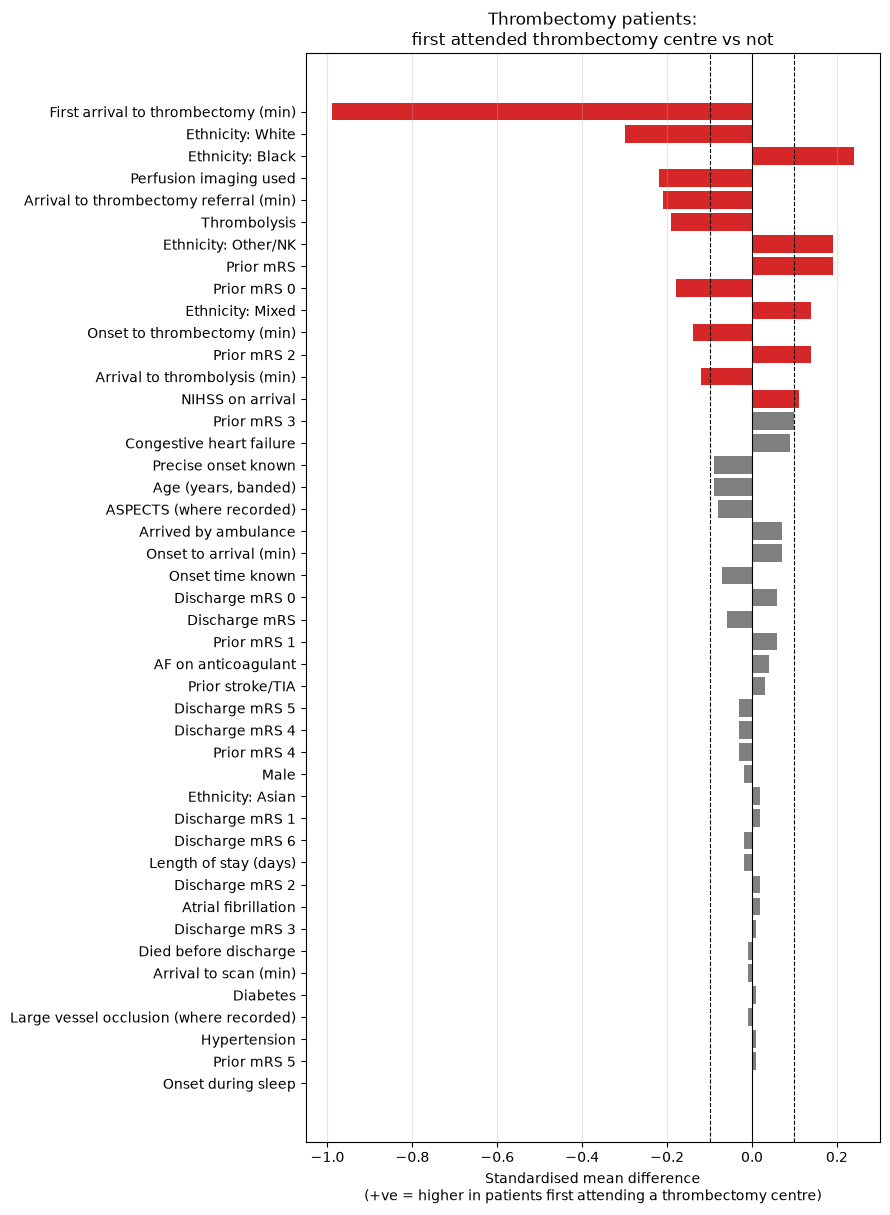

In [12]:
# Plot standardised mean differences (|SMD| > 0.1 is a common threshold for a meaningful imbalance)
# Sort by |SMD| ascending so the largest imbalance appears at the top of the barh chart
plot_data = comparison['SMD'].dropna()
plot_data = plot_data.reindex(plot_data.abs().sort_values().index)
colours = np.where(plot_data.abs() > 0.1, 'tab:red', 'tab:grey')

fig, ax = plt.subplots(figsize=(9, 0.25 * len(plot_data) + 1))
ax.barh(plot_data.index, plot_data.values, color=colours)
for x in (-0.1, 0.1):
    ax.axvline(x, color='k', linestyle='--', linewidth=0.8)
ax.axvline(0, color='k', linewidth=0.8)
ax.set_xlabel('Standardised mean difference\n(+ve = higher in patients first attending a thrombectomy centre)')
ax.set_title('Thrombectomy patients:\nfirst attended thrombectomy centre vs not')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('output/thrombectomy_by_first_centre_smd.png', dpi=300, bbox_inches='tight')
plt.show()

**Results:** 14 characteristics exceed the ±0.1 threshold. In order of size: first arrival to thrombectomy time (−0.99, far larger than any other), White ethnicity (−0.30), Black ethnicity (0.24), perfusion imaging (−0.22), arrival to thrombectomy referral time (−0.21), prior mRS (0.19), thrombolysis (−0.19), Other/not known ethnicity (0.19), prior mRS 0 (−0.18), Mixed ethnicity (0.14), onset to thrombectomy time (−0.14), prior mRS 2 (0.14), arrival to thrombolysis time (−0.12) and NIHSS (0.11). Prior mRS 3, precise onset known, age and congestive heart failure are just inside the threshold. All other characteristics are within ±0.1.

## Thrombolysis and transfer for thrombectomy by non-thrombectomy hospital

Compares the non-thrombectomy hospitals on how often they give thrombolysis and how often they transfer patients to another hospital for thrombectomy. Each rate is calculated for all stroke admissions in 2024–2025, and for ischaemic stroke with NIHSS > 10, the patients most likely to be suitable for thrombectomy. The transfer rate is also calculated for the ischaemic NIHSS > 10 patients who were thrombolysed.

"Transferred" means a transfer to another hospital for thrombectomy is recorded in SSNAP. Across these centres, 4,024 of the 5,025 transferred patients (80%) went on to have thrombectomy, and 173 patients had thrombectomy recorded without a transfer.

**What this cell does:** Calculates, for each non-thrombectomy hospital, the number of patients, the percentage given thrombolysis and the percentage transferred for thrombectomy. This is done for three groups: all stroke admissions; ischaemic stroke with NIHSS > 10; and ischaemic stroke with NIHSS > 10 who were also thrombolysed (for this group only the transfer rate is shown, as all were thrombolysed). Hospitals are sorted by their transfer rate for ischaemic stroke with NIHSS > 10, highest first, and the table is saved to `output/non_thrombectomy_centre_rates.csv`.

In [13]:
# Start again from all_data: data_filtered has already been restricted above
year_mask = (all_data['year'] >= min_year) & (all_data['year'] <= max_year)
non_tc_all = all_data[year_mask & (all_data['thrombectomy_centre'] == 0)]
non_tc_severe = non_tc_all[
    (non_tc_all['infarction'] == 1) & (non_tc_all['stroke_severity'] > 10)
]
# Ischaemic NIHSS > 10 patients who were also thrombolysed
non_tc_severe_ivt = non_tc_severe[non_tc_severe['thrombolysis'] == 1]

def centre_rates(df, label):
    """Patients, % thrombolysed and % transferred for thrombectomy per stroke team."""
    rates = df.groupby('stroke_team').agg(
        n=('thrombolysis', 'size'),
        thrombolysed=('thrombolysis', 'mean'),
        transferred=('transfer_used', 'mean'),
    )
    rates[['thrombolysed', 'transferred']] *= 100
    rates.columns = [
        f'Patients ({label})',
        f'Thrombolysed % ({label})',
        f'Transferred % ({label})',
    ]
    return rates

# For the thrombolysed subset only the transfer rate is informative (all are thrombolysed)
ivt_rates = centre_rates(non_tc_severe_ivt, 'ischaemic NIHSS>10 thrombolysed').drop(
    columns='Thrombolysed % (ischaemic NIHSS>10 thrombolysed)')
non_tc_rates = (
    centre_rates(non_tc_all, 'all')
    .join(centre_rates(non_tc_severe, 'ischaemic NIHSS>10'))
    .join(ivt_rates)
)
non_tc_rates = non_tc_rates.sort_values(
    'Transferred % (ischaemic NIHSS>10)', ascending=False)
non_tc_rates.to_csv('output/non_thrombectomy_centre_rates.csv')

pd.set_option('display.max_rows', 120)
non_tc_rates.round(1)

,Patients (all),Thrombolysed % (all),Transferred % (all),Patients (ischaemic NIHSS>10),Thrombolysed % (ischaemic NIHSS>10),Transferred % (ischaemic NIHSS>10),Patients (ischaemic NIHSS>10 thrombolysed),Transferred % (ischaemic NIHSS>10 thrombolysed)
stroke_team,,,,,,,,
MTU,987,9.0,5.3,98,27.6,37.8,27,37.0
EUB,1134,23.5,7.7,194,55.2,36.6,107,43.9
LSO,1215,9.6,9.1,216,25.5,36.6,55,45.5
AGD,1684,17.5,7.2,251,43.0,35.9,108,52.8
ORC,1103,14.4,9.8,225,26.2,33.3,59,44.1
FNY,1710,13.5,8.1,280,37.9,33.2,106,56.6
YZR,1646,6.1,6.1,180,19.4,32.8,35,42.9
YWT,1454,18.2,7.1,229,43.7,32.3,100,48.0
FQE,1210,16.2,4.5,140,42.9,31.4,60,45.0


**Results:** There are 87 non-thrombectomy centres, with 110,090 admissions in total, 18,296 with ischaemic stroke and NIHSS > 10, and 5,789 of those thrombolysed.

For ischaemic stroke with NIHSS > 10, the highest transfer rates are at MTU (37.8%), EUB and LSO (both 36.6%) and AGD (35.9%). The lowest are at QVM (0.6%), GAJ (5.5%), STK (7.6%) and WVO (7.7%).

QVM's 0.6% should be checked. Of its ischaemic NIHSS > 10 patients, 6.2% have thrombectomy recorded, so transfers may be under-recorded there. Some centres are small (six have fewer than 70 ischaemic NIHSS > 10 patients, the smallest being GOE with 44), so their rates are less precise.

Among thrombolysed ischaemic NIHSS > 10 patients, the highest transfer rates are at MGQ (60.0%), XOG (57.5%), FNY (56.6%) and AGD (52.8%). The lowest are at QVM (1.7%), WVO (2.5%), GAJ (11.8%) and XJW (11.8%). Centres have between 10 and 154 thrombolysed ischaemic NIHSS > 10 patients (median 60), so this rate is less precise than the others; MGQ's 60% is based on 20 patients. WVO is unusual: 7.7% of its ischaemic NIHSS > 10 patients are transferred overall, but only 2.5% of those thrombolysed.

**What this cell does:** Summarises how much each of the five rates varies between hospitals (lowest, quartiles and highest), alongside the overall (pooled) rate for all patients together and the ratio of the highest to the lowest hospital. It also checks for missing data, and gives the correlation between a hospital's thrombolysis rate and its transfer rate for ischaemic stroke with NIHSS > 10.

In [14]:
# Spread of rates across non-thrombectomy centres, and the pooled rate for comparison
rate_cols = [c for c in non_tc_rates.columns if '%' in c]
spread = non_tc_rates[rate_cols].describe(percentiles=[0.25, 0.5, 0.75]).T
spread = spread[['count', 'min', '25%', '50%', '75%', 'max']]
# Pooled rate: every patient in the group, ignoring which centre they attended
groups = {
    'all': non_tc_all,
    'ischaemic NIHSS>10': non_tc_severe,
    'ischaemic NIHSS>10 thrombolysed': non_tc_severe_ivt,
}
spread['Pooled %'] = [
    groups[col.split('(')[1].rstrip(')')][
        'thrombolysis' if col.startswith('Thrombolysed') else 'transfer_used'
    ].mean() * 100
    for col in rate_cols
]
print('Patients:', len(non_tc_all), '| ischaemic NIHSS>10:', len(non_tc_severe),
      '| ischaemic NIHSS>10 thrombolysed:', len(non_tc_severe_ivt))
print('Thrombolysed ischaemic NIHSS>10 patients per centre:',
      non_tc_rates['Patients (ischaemic NIHSS>10 thrombolysed)'].describe().round(0).to_dict())
print('Missing thrombolysis:', non_tc_all['thrombolysis'].isna().sum(),
      '| missing transfer_used:', non_tc_all['transfer_used'].isna().sum())
print('Correlation of thrombolysis % and transfer % (ischaemic NIHSS>10):',
      round(non_tc_rates['Thrombolysed % (ischaemic NIHSS>10)'].corr(
          non_tc_rates['Transferred % (ischaemic NIHSS>10)']), 2))
spread.round(1)

Patients: 110090 | ischaemic NIHSS>10: 18296 | ischaemic NIHSS>10 thrombolysed: 5789
Thrombolysed ischaemic NIHSS>10 patients per centre: {'count': 87.0, 'mean': 67.0, 'std': 35.0, 'min': 10.0, '25%': 41.0, '50%': 60.0, '75%': 90.0, 'max': 154.0}
Missing thrombolysis: 0 | missing transfer_used: 0
Correlation of thrombolysis % and transfer % (ischaemic NIHSS>10): 0.22


,count,min,25%,50%,75%,max,Pooled %
Thrombolysed % (all),87.0,6.1,11.1,13.4,15.1,23.6,13.5
Transferred % (all),87.0,0.2,3.2,4.4,5.7,9.8,4.6
Thrombolysed % (ischaemic NIHSS>10),87.0,17.3,26.2,30.9,36.1,55.2,31.6
Transferred % (ischaemic NIHSS>10),87.0,0.6,14.8,20.7,27.3,37.8,20.3
Transferred % (ischaemic NIHSS>10 thrombolysed),87.0,1.7,27.8,36.1,45.2,60.0,35.4


**Results:** No values are missing for thrombolysis or transfer.

| Rate across 87 centres | Median [IQR] | Range | Pooled |
|---|---|---|---|
| Thrombolysed, all patients | 13.4% [11.1–15.1] | 6.1–23.6% | 13.5% |
| Thrombolysed, ischaemic NIHSS > 10 | 30.9% [26.2–36.1] | 17.3–55.2% | 31.6% |
| Transferred, all patients | 4.4% [3.2–5.7] | 0.2–9.8% | 4.6% |
| Transferred, ischaemic NIHSS > 10 | 20.7% [14.8–27.3] | 0.6–37.8% | 20.3% |
| Transferred, ischaemic NIHSS > 10 and thrombolysed | 36.1% [27.8–45.2] | 1.7–60.0% | 35.4% |

Thrombolysis rates vary about 3–4-fold between centres. Transfer rates vary much more. The highest-to-lowest ratio is about 60, but that is driven by QVM. Without it, transfer rates for ischaemic NIHSS > 10 still vary about 7-fold (5.5% to 37.8%), and the middle half of centres spans 14.8% to 27.3%. Centres that thrombolyse more tend to transfer slightly more (correlation 0.22), so the two rates are only weakly linked.

Thrombolysed ischaemic NIHSS > 10 patients are transferred more often than ischaemic NIHSS > 10 patients overall (pooled 35.4% versus 20.3%), and this rate varies even more between centres: the middle half spans 27.8% to 45.2%.

**What this cell does:** Draws a histogram for each of the five hospital-level rates: each bar counts the hospitals whose rate falls within a 2.5-percentage-point range. The left column shows % thrombolysed and the right column % transferred, with each column on the same scale so the patient groups can be compared. There is no thrombolysis panel for the thrombolysed group (it would be 100%). The dashed line marks the median hospital and the dotted line the overall rate for all patients. The figure is saved to `output/non_thrombectomy_centre_rates_hist.png`.

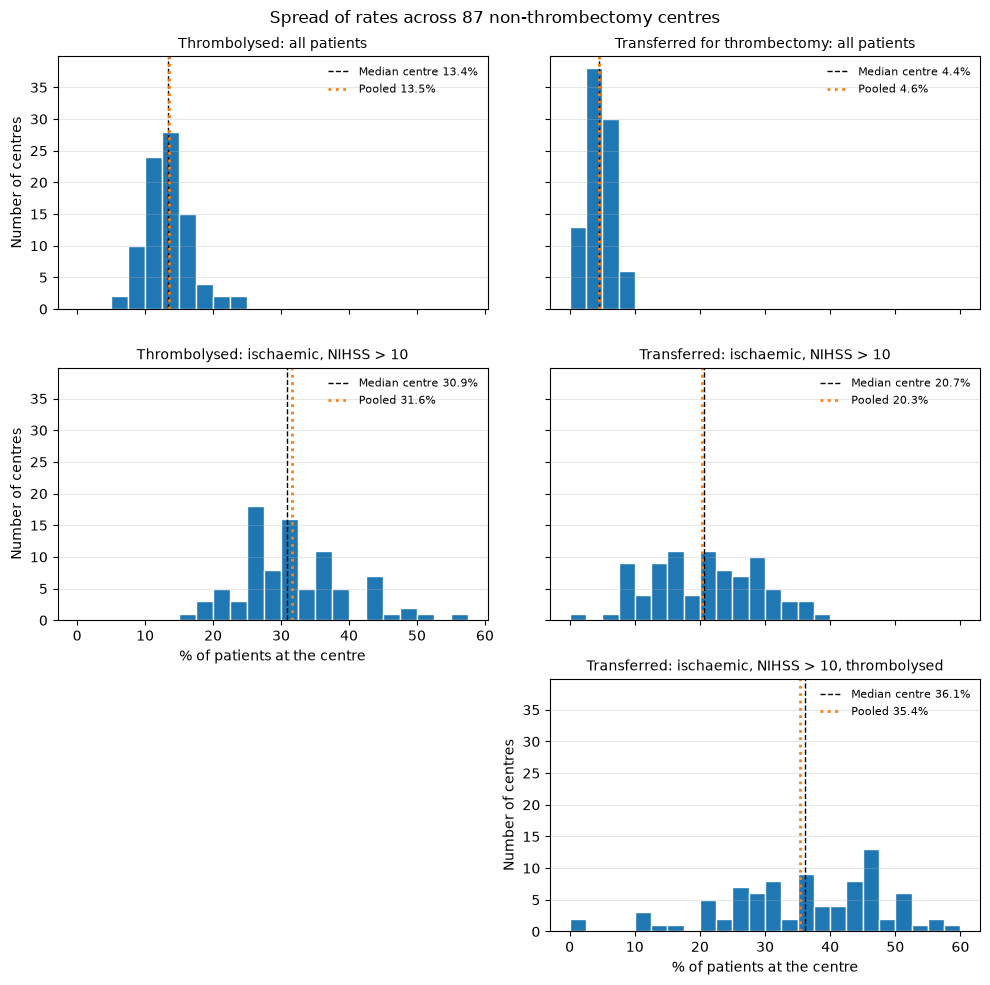

In [15]:
# Histograms of the centre-level rates (one value per non-thrombectomy centre)
# Left column: % thrombolysed; right column: % transferred for thrombectomy
panels = {
    (0, 0): ('Thrombolysed % (all)', 'Thrombolysed: all patients'),
    (0, 1): ('Transferred % (all)', 'Transferred for thrombectomy: all patients'),
    (1, 0): ('Thrombolysed % (ischaemic NIHSS>10)', 'Thrombolysed: ischaemic, NIHSS > 10'),
    (1, 1): ('Transferred % (ischaemic NIHSS>10)', 'Transferred: ischaemic, NIHSS > 10'),
    (2, 1): ('Transferred % (ischaemic NIHSS>10 thrombolysed)',
             'Transferred: ischaemic, NIHSS > 10, thrombolysed'),
}

# Same 2.5-point bins within each column so the patient groups line up
def bins_for(prefix):
    cols = [col for col, _ in panels.values() if col.startswith(prefix)]
    upper = np.ceil(non_tc_rates[cols].max().max() / 2.5) * 2.5
    return np.arange(0, upper + 2.5, 2.5)
bins = {'Thrombolysed': bins_for('Thrombolysed'), 'Transferred': bins_for('Transferred')}

fig, axes = plt.subplots(3, 2, figsize=(10, 10), sharex='col', sharey=True)
for (row, col_idx), (col, title) in panels.items():
    ax = axes[row, col_idx]
    values = non_tc_rates[col].dropna()
    ax.hist(values, bins=bins[col.split(' ')[0]], color='tab:blue',
            edgecolor='white', linewidth=1)
    ax.axvline(values.median(), color='k', linestyle='--', linewidth=1,
               label=f'Median centre {values.median():.1f}%')
    ax.axvline(spread.loc[col, 'Pooled %'], color='tab:orange', linestyle=':',
               linewidth=2, label=f"Pooled {spread.loc[col, 'Pooled %']:.1f}%")
    ax.set_title(title, fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    ax.legend(frameon=False, fontsize=8)

# No thrombolysis panel for the thrombolysed subset (it would be 100% everywhere)
axes[2, 0].axis('off')
axes[1, 0].set_xlabel('% of patients at the centre')
axes[1, 0].xaxis.set_tick_params(labelbottom=True)
axes[2, 1].set_xlabel('% of patients at the centre')
for ax in axes[:, 0]:
    ax.set_ylabel('Number of centres')
axes[2, 1].set_ylabel('Number of centres')
axes[2, 1].yaxis.set_tick_params(labelleft=True)
fig.suptitle(f'Spread of rates across {len(non_tc_rates)} non-thrombectomy centres')
plt.tight_layout()
plt.savefig('output/non_thrombectomy_centre_rates_hist.png', dpi=300, bbox_inches='tight')
plt.show()

**Results:** For all patients, both rates are tightly grouped: most centres thrombolyse 10–17.5% of admissions and transfer 2.5–7.5% for thrombectomy. Among ischaemic strokes with NIHSS > 10 the spread is much wider. Thrombolysis clusters around 25–37.5% with a long right tail up to 55%. Transfer rates spread almost evenly from about 7.5% to 35%, with no clear peak, plus one outlying centre near 0% (QVM, likely under-recorded; see above). For thrombolysed ischaemic NIHSS > 10 patients, transfer rates shift further right and spread further still, mostly between about 20% and 50%, with a cluster around 45–47.5% and two centres near 0% (QVM and WVO). In every panel the median centre and the pooled rate are close, so no single large centre dominates the pooled figure.

### Does variation in thrombolysis explain variation in transfers?

For ischaemic stroke with NIHSS > 10 at non-thrombectomy centres, this checks whether centres that thrombolyse more patients also transfer more for thrombectomy, and how much of the between-centre variation in transfer rate would remain if every centre thrombolysed at the same rate.

**What this cell does:** Asks, in two ways, whether hospitals that give more thrombolysis also transfer more patients for thrombectomy (ischaemic stroke with NIHSS > 10; one value per hospital):

1. **Association:** fits a straight line of transfer rate against thrombolysis rate across hospitals, and reports the correlation and R² (the share of the differences in transfer rate between hospitals that is accounted for by thrombolysis rate).
2. **Standardisation:** calculates what each hospital's transfer rate would be if every hospital thrombolysed the same proportion of patients (the overall rate), keeping each hospital's own transfer rates for thrombolysed and non-thrombolysed patients. If thrombolysis drove the differences in transfer, these standardised rates would vary much less than the actual rates.

The left panel plots thrombolysis rate against transfer rate; the right panel plots each hospital's actual transfer rate against its standardised rate (points on the dashed line are unchanged). The figure is saved to `output/non_thrombectomy_centre_thrombolysis_vs_transfer.png`.

Linear fit: transfer % = 13.3 + 0.23 x thrombolysis %
Pearson r = 0.22 (R² = 0.049, p = 0.040); Spearman rho = 0.20 (p = 0.063)
Pooled thrombolysis rate used for standardising: 31.6%
SD across centres: observed 8.2, standardised 7.8 percentage points
IQR across centres: observed 14.8–27.3%, standardised 15.8–26.2%
Between-centre variance removed by standardising thrombolysis: 9.1%
Correlation of transfer rate in thrombolysed vs non-thrombolysed patients: 0.47


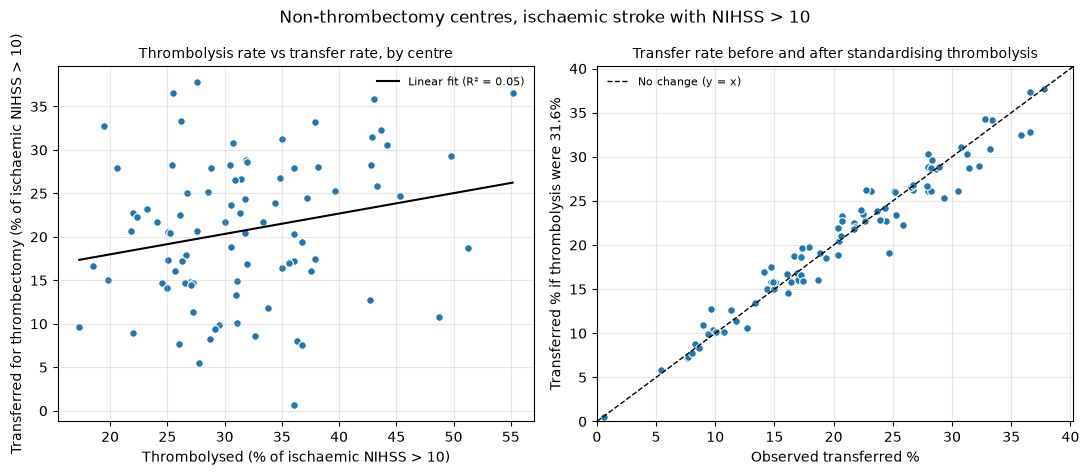

In [16]:
from scipy import stats

# Does a centre's use of thrombolysis explain its transfer rate? (ischaemic NIHSS > 10)
x = non_tc_rates['Thrombolysed % (ischaemic NIHSS>10)']
y = non_tc_rates['Transferred % (ischaemic NIHSS>10)']
fit = stats.linregress(x, y)
rho, rho_p = stats.spearmanr(x, y)

# Transfer rate within each centre, separately for patients with and without thrombolysis
by_ivt = (non_tc_severe.groupby(['stroke_team', 'thrombolysis'])['transfer_used']
          .mean().unstack() * 100)
by_ivt.columns = ['Transferred % (not thrombolysed)', 'Transferred % (thrombolysed)']

# Standardise: each centre's expected transfer rate if it thrombolysed at the pooled rate,
# keeping its own transfer rates for thrombolysed and non-thrombolysed patients
p_pooled = non_tc_severe['thrombolysis'].mean()
by_ivt['Observed transferred %'] = y
by_ivt['Standardised transferred %'] = (
    p_pooled * by_ivt['Transferred % (thrombolysed)']
    + (1 - p_pooled) * by_ivt['Transferred % (not thrombolysed)']
)

obs, std = by_ivt['Observed transferred %'], by_ivt['Standardised transferred %']
print(f'Linear fit: transfer % = {fit.intercept:.1f} + {fit.slope:.2f} x thrombolysis %')
print(f'Pearson r = {fit.rvalue:.2f} (R² = {fit.rvalue**2:.3f}, p = {fit.pvalue:.3f}); '
      f'Spearman rho = {rho:.2f} (p = {rho_p:.3f})')
print(f'Pooled thrombolysis rate used for standardising: {p_pooled * 100:.1f}%')
print(f'SD across centres: observed {obs.std():.1f}, standardised {std.std():.1f} percentage points')
print(f'IQR across centres: observed {obs.quantile(0.25):.1f}–{obs.quantile(0.75):.1f}%, '
      f'standardised {std.quantile(0.25):.1f}–{std.quantile(0.75):.1f}%')
print(f'Between-centre variance removed by standardising thrombolysis: '
      f'{(1 - std.var() / obs.var()) * 100:.1f}%')
print(f'Correlation of transfer rate in thrombolysed vs non-thrombolysed patients: '
      f'{by_ivt.iloc[:, 0].corr(by_ivt.iloc[:, 1]):.2f}')

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))

ax = axes[0]
ax.scatter(x, y, s=30, color='tab:blue', edgecolor='white', linewidth=0.8)
xs = np.linspace(x.min(), x.max(), 50)
ax.plot(xs, fit.intercept + fit.slope * xs, color='k', linewidth=1.5,
        label=f'Linear fit (R² = {fit.rvalue**2:.2f})')
ax.set_xlabel('Thrombolysed (% of ischaemic NIHSS > 10)')
ax.set_ylabel('Transferred for thrombectomy (% of ischaemic NIHSS > 10)')
ax.set_title('Thrombolysis rate vs transfer rate, by centre', fontsize=10)
ax.grid(alpha=0.3)
ax.legend(frameon=False, fontsize=8)

ax = axes[1]
ax.scatter(obs, std, s=30, color='tab:blue', edgecolor='white', linewidth=0.8)
lims = [0, max(obs.max(), std.max()) + 2.5]
ax.plot(lims, lims, color='k', linestyle='--', linewidth=1, label='No change (y = x)')
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel('Observed transferred %')
ax.set_ylabel(f'Transferred % if thrombolysis were {p_pooled * 100:.1f}%')
ax.set_title('Transfer rate before and after standardising thrombolysis', fontsize=10)
ax.grid(alpha=0.3)
ax.legend(frameon=False, fontsize=8)

fig.suptitle('Non-thrombectomy centres, ischaemic stroke with NIHSS > 10')
plt.tight_layout()
plt.savefig('output/non_thrombectomy_centre_thrombolysis_vs_transfer.png', dpi=300,
            bbox_inches='tight')
plt.show()

**Results:** Variation in thrombolysis explains very little of the variation in transfers for thrombectomy.

* **Association:** centres that thrombolyse more do transfer slightly more: each extra 10 percentage points of thrombolysis goes with about 2.3 more points of transfer (Pearson r = 0.22, p = 0.04; Spearman rho = 0.20, p = 0.06). But R² is only 0.05, so thrombolysis rate accounts for about 5% of the between-centre variance in transfer rate. The left panel shows a wide scatter around a shallow line.
* **Standardisation:** if every centre thrombolysed at the pooled rate (31.6%), the spread of transfer rates would barely change: SD 8.2 → 7.8 percentage points and IQR 14.8–27.3% → 15.8–26.2%. This removes about 9% of the between-centre variance. In the right panel almost every centre sits close to the no-change line.
* **Centre transfer practice:** a centre's transfer rate for thrombolysed patients correlates with its rate for non-thrombolysed patients (r = 0.47). Centres that transfer a lot tend to do so whether or not the patient was thrombolysed, which suggests the variation comes mainly from each centre's own transfer practice (or its patients, pathways and distance to a thrombectomy centre) rather than from its use of thrombolysis.

These are crude, centre-level comparisons with no adjustment for case mix (for example, large vessel occlusion, onset time or travel time), so they show association, not cause.

## Do stroke teams differ in which patients they select for thrombectomy?

This section looks at patients who first arrived at a non-thrombectomy hospital, for whom receiving thrombectomy almost always means transfer to a thrombectomy unit. It asks two questions:

1. Do teams differ in **how many** patients they send for thrombectomy, for the same patients?
2. Do teams differ in **which** patients they send: do some teams give more or less weight to age, prior disability, time since onset or stroke severity?

To answer these, a machine learning model (XGBoost) is trained to predict, for each patient, the chance of receiving thrombectomy from their characteristics, the stroke team they first attended and the thrombectomy unit that team transfers to. The model's settings are optimised automatically (with a tool called Optuna), and its predictions are explained with SHAP. The model is then used to predict what **every team would do with the same group of patients**, so that differences between teams are not due to differences in the patients they see.

Note: these cells use all patients with ischaemic stroke and NIHSS > 10 (2024–2025), not only those who received thrombectomy.

**What this cell does:** Selects patients who first arrived at a non-thrombectomy hospital, and creates yes/no flags for some characteristics used later: aged 80 or over, prior mRS 2 or more, NIHSS 21 or more, arrival more than 4 hours after onset (or onset-to-arrival time unknown), and onset time not precisely known. It then cross-tabulates recorded transfer against thrombectomy, to check that thrombectomy is a good marker of transfer.

In [17]:
import warnings
from scipy import stats

# Patients first attending a non-thrombectomy centre
transfer_cohort = data_filtered[data_filtered['thrombectomy_centre'] == 0].copy()

# 0/1 patient characteristic flags
transfer_cohort['age80'] = (transfer_cohort['age'] >= 80).astype(int)
transfer_cohort['mrs2'] = (transfer_cohort['prior_disability'] >= 2).astype(int)
transfer_cohort['nihss21'] = (transfer_cohort['stroke_severity'] >= 21).astype(int)
transfer_cohort['late'] = ((transfer_cohort['onset_to_arrival_time'] > 240) |
                           transfer_cohort['onset_to_arrival_time'].isna()).astype(int)
transfer_cohort['imprecise'] = (transfer_cohort['precise_onset_known'] == 0).astype(int)
transfer_cohort['team'] = transfer_cohort['stroke_team'].astype(str)

selection_features = ['age80', 'mrs2', 'nihss21', 'late', 'imprecise']

print(f"Patients: {len(transfer_cohort):,}; teams: {transfer_cohort['team'].nunique()}")
pd.crosstab(transfer_cohort['transfer_used'], transfer_cohort['thrombectomy'])

Patients: 18,296; teams: 87


thrombectomy,0,1
transfer_used,,
0,14446,139
1,600,3111


**Results:** 18,296 patients first attended one of 87 non-thrombectomy teams. 3,111 were transferred and received thrombectomy, 600 were transferred but did not receive thrombectomy, and 139 received thrombectomy with no transfer recorded. Thrombectomy is therefore used below as the measure of transfer for thrombectomy.

**What this cell does:** Calculates the proportion of patients receiving thrombectomy for each team, and summarises how this varies between teams.

In [18]:
team_rates = transfer_cohort.groupby('team').agg(
    patients=('thrombectomy', 'size'), thrombectomy_rate=('thrombectomy', 'mean'))
team_rates.describe().round(3)

,patients,thrombectomy_rate
count,87.000,87.000
mean,210.299,0.180
std,103.485,0.072
min,44.000,0.055
25%,133.500,0.128
50%,200.000,0.174
75%,265.500,0.235
max,458.000,0.357


**Results:** Team thrombectomy rates range from 5.5% to 35.7% (median 17.4%; interquartile range 12.8–23.5%). Teams have between 44 and 458 patients (median 200).

**What this cell does:** Prepares the data for the model and optimises the model's settings.

- **Information given to the model:** 15 patient characteristics (age, sex, NIHSS, prior mRS, time from onset to arrival, whether onset time is known or precisely known, onset during sleep, arrival by ambulance, and comorbidities), the stroke team first attended, and the thrombectomy unit that team transfers to (21 units; the 107 patients whose team has no recorded unit have none). Each team transfers to one unit, so giving the model both lets it separate the part of a team's behaviour that is shared with other teams using the same unit from the part that is specific to the team. Missing values (mainly onset-to-arrival time, missing for 18% of patients) are handled by the model directly.
- **Training and test sets:** 80% of patients are used to build the model (the training set). The other 20% are kept aside to test it on patients it has not seen (the test set).
- **Performance measure:** the ROC AUC, the probability that the model gives a higher predicted chance of thrombectomy to a randomly chosen patient who received it than to one who did not (0.5 = no better than chance; 1.0 = perfect).
- **Optimising the settings:** the model has settings such as the number of trees, how many levels of rules each tree can have, and how quickly it learns. Optuna tries 50 combinations and keeps the one with the best ROC AUC in 5-fold cross-validation: the training set is split into five parts, the model is built on four and tested on the fifth, in turn, and the five results are averaged.
- This takes about 5 minutes, so the chosen settings are saved to `output/xgb_tuning.json`. If `retune_model` is False, the saved settings are used instead of optimising again.

In [19]:
import optuna
import json
import os
import xgboost as xgb
from sklearn.model_selection import StratifiedKFold, train_test_split, cross_val_score
from sklearn.metrics import roc_auc_score, brier_score_loss

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

patient_features = [
    'age', 'male', 'stroke_severity', 'prior_disability', 'onset_to_arrival_time',
    'onset_known', 'precise_onset_known', 'onset_during_sleep', 'arrive_by_ambulance',
    'congestive_heart_failure', 'hypertension', 'atrial_fibrillation', 'diabetes',
    'prior_stroke_tia', 'afib_anticoagulant']

# Patient characteristics plus one 0/1 column per stroke team and one per thrombectomy unit
# (MT_transfer_unit, the unit the team transfers to; all 0 where the unit is not known)
team_dummies = pd.get_dummies(transfer_cohort['stroke_team'], prefix='team', dtype=float)
team_cols = list(team_dummies.columns)
unit_dummies = pd.get_dummies(transfer_cohort['MT_transfer_unit'], prefix='unit', dtype=float)
unit_cols = list(unit_dummies.columns)
X = pd.concat([transfer_cohort[patient_features].astype(float), team_dummies, unit_dummies], axis=1)
y = transfer_cohort['thrombectomy'].astype(int).values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def objective(trial):
    params = dict(
        n_estimators=trial.suggest_int('n_estimators', 100, 1000),
        learning_rate=trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        max_depth=trial.suggest_int('max_depth', 2, 8),
        min_child_weight=trial.suggest_float('min_child_weight', 1, 20, log=True),
        subsample=trial.suggest_float('subsample', 0.5, 1.0),
        colsample_bytree=trial.suggest_float('colsample_bytree', 0.3, 1.0),
        reg_lambda=trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
        reg_alpha=trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
    )
    model = xgb.XGBClassifier(**params, tree_method='hist', n_jobs=-1,
                              random_state=42, eval_metric='logloss')
    return cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc').mean()

# Tuning is slow (~5 min), so the result is saved and reloaded on later runs.
# Set retune_model = True at the start of the notebook to re-tune (e.g. after changing the data);
# a new tuning is also run if no saved file exists.
tuning_file = 'output/xgb_tuning.json'
if os.path.exists(tuning_file) and not retune_model:
    with open(tuning_file) as f:
        tuning = json.load(f)
    print(f'Loaded tuned hyperparameters from {tuning_file}')
else:
    study = optuna.create_study(direction='maximize',
                                sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=100)
    tuning = {'best_params': study.best_params, 'best_value': study.best_value}
    with open(tuning_file, 'w') as f:
        json.dump(tuning, f, indent=2)
    print(f'Saved tuned hyperparameters to {tuning_file}')

best_params = dict(tuning['best_params'], tree_method='hist', n_jobs=-1,
                   random_state=42, eval_metric='logloss')
print(f"Best cross-validated ROC AUC: {tuning['best_value']:.3f}")
pd.Series(tuning['best_params']).round(3)

Saved tuned hyperparameters to output/xgb_tuning.json
Best cross-validated ROC AUC: 0.843


n_estimators        497.000
learning_rate         0.106
max_depth             2.000
min_child_weight     10.461
subsample             0.939
colsample_bytree      0.766
reg_lambda            1.147
reg_alpha             0.048
dtype: float64

**Results:** The settings were re-optimised on the current data, including the thrombectomy unit. The best of 50 combinations had a cross-validated ROC AUC of 0.843. The chosen model adds together 497 small trees, each with at most two levels of yes/no rules, so it can capture combinations of two characteristics (for example, a team together with patient age). It also includes settings that stop it fitting small groups of patients too closely.

**Note:** these settings were saved to `output/xgb_tuning.json`. `retune_model` is set to False, so later runs of the notebook re-use them (the output above will then say the settings were loaded rather than saved); set it to True to optimise the settings again.

**What this cell does:** Builds the model on the training set and tests it on the 20% test set:

- **ROC AUC** (see above): how well the model separates patients who did and did not receive thrombectomy.
- **Brier score:** the average squared difference between the predicted chance and what actually happened (0 = perfect; lower is better).
- **Calibration:** whether predicted chances match reality. Patients are divided into ten equal-sized groups (deciles) by their predicted chance, and the average predicted chance in each group is compared with the proportion who actually received thrombectomy.

For comparison, two simpler models are also built: one with patient characteristics and thrombectomy unit but no team, and one with patient characteristics only. This shows how much knowing the unit and the team adds to the prediction.

In [20]:
model_train = xgb.XGBClassifier(**best_params).fit(X_train, y_train)
p_test = model_train.predict_proba(X_test)[:, 1]

model_no_team = xgb.XGBClassifier(**best_params).fit(X_train[patient_features], y_train)
p_test_no_team = model_no_team.predict_proba(X_test[patient_features])[:, 1]

model_unit = xgb.XGBClassifier(**best_params).fit(X_train[patient_features + unit_cols], y_train)
p_test_unit = model_unit.predict_proba(X_test[patient_features + unit_cols])[:, 1]

print(f'Test ROC AUC (patients + team + unit): {roc_auc_score(y_test, p_test):.3f}')
print(f'Test ROC AUC (patients + unit, no team): {roc_auc_score(y_test, p_test_unit):.3f}')
print(f'Test ROC AUC (patients only): {roc_auc_score(y_test, p_test_no_team):.3f}')
print(f'Brier score: {brier_score_loss(y_test, p_test):.3f}')
print(f'Observed rate {y_test.mean():.3f}; mean predicted {p_test.mean():.3f}')

# Calibration by decile of predicted probability
calibration = pd.DataFrame({'Predicted': p_test, 'Observed': y_test})
calibration['Decile'] = pd.qcut(calibration['Predicted'], 10, labels=False) + 1
calibration.groupby('Decile').mean().round(3).T

Test ROC AUC (patients + team + unit): 0.834
Test ROC AUC (patients + unit, no team): 0.832
Test ROC AUC (patients only): 0.814
Brier score: 0.115
Observed rate 0.178; mean predicted 0.183


Decile,1,2,3,4,5,6,7,8,9,10
Predicted,0.002,0.007,0.017,0.039,0.082,0.146,0.220,0.312,0.419,0.583
Observed,0.000,0.008,0.016,0.030,0.096,0.167,0.219,0.292,0.426,0.522


**Results:** The model separates patients well (ROC AUC 0.834 in the test set) and its predictions match reality: the average predicted chance (18.3%) is close to the actual rate (17.8%), and actual rates follow predicted chances across the ten groups, from 0% in the lowest group to 52% in the highest (where the predicted chance, 58%, was slightly too high). Without team or unit the ROC AUC falls to 0.814, so the hospital a patient first attends adds to the prediction beyond their own characteristics. With the unit but no team the ROC AUC is 0.832, almost the same as with both: knowing which thrombectomy unit a team transfers to captures nearly all of the predictive value of knowing the team.

**What this cell does:** Explains the model's predictions with SHAP. For each patient, SHAP splits the model's prediction into a contribution from each piece of information: how much it pushed that patient's predicted chance of thrombectomy up (positive) or down (negative) compared with an average patient. Contributions are on the log-odds scale: +0.7 roughly doubles the odds of thrombectomy and −0.7 roughly halves them. The model is rebuilt on all patients for this. The contributions of the 87 team columns are added together into one **stroke team** contribution, and those of the 21 unit columns into one **thrombectomy unit** contribution.

- **Panel A:** the average size of each contribution, ignoring direction (mean |SHAP|), a measure of overall importance. Team is orange, unit green.
- **Panel B:** each team's average contribution, over and above its unit.
- **Panel C:** each thrombectomy unit's average contribution.

The figure is saved to `output/xgb_shap.png`.

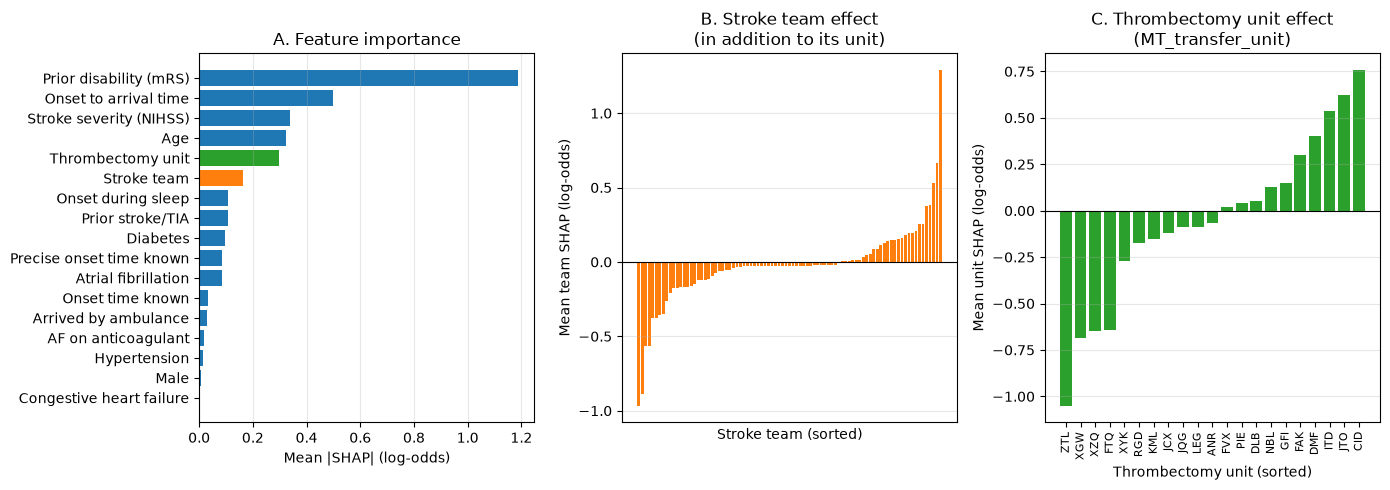

Mean |SHAP|:
prior_disability            1.189
onset_to_arrival_time       0.497
stroke_severity             0.340
age                         0.322
Thrombectomy unit           0.296
Stroke team                 0.162
onset_during_sleep          0.107
prior_stroke_tia            0.106
diabetes                    0.095
precise_onset_known         0.087
atrial_fibrillation         0.085
onset_known                 0.034
arrive_by_ambulance         0.029
afib_anticoagulant          0.017
hypertension                0.013
male                        0.007
congestive_heart_failure    0.004
Team SHAP 10th/50th/90th centile: -0.23 / -0.02 / 0.19 (range -0.97 to 1.29)
Unit SHAP 10th/50th/90th centile: -0.65 / -0.06 / 0.53 (range -1.05 to 0.76)
Team + unit SHAP, 10th/90th centile team: -0.71 / 0.56


In [21]:
import shap

model = xgb.XGBClassifier(**best_params).fit(X, y)
shap_values = shap.TreeExplainer(model).shap_values(X)
shap_df = pd.DataFrame(shap_values, columns=X.columns, index=X.index)
shap_df['Stroke team'] = shap_df[team_cols].sum(axis=1)
shap_df['Thrombectomy unit'] = shap_df[unit_cols].sum(axis=1)

feature_labels = {
    'prior_disability': 'Prior disability (mRS)', 'onset_to_arrival_time': 'Onset to arrival time',
    'stroke_severity': 'Stroke severity (NIHSS)', 'age': 'Age', 'onset_during_sleep': 'Onset during sleep',
    'prior_stroke_tia': 'Prior stroke/TIA', 'diabetes': 'Diabetes',
    'precise_onset_known': 'Precise onset time known', 'atrial_fibrillation': 'Atrial fibrillation',
    'onset_known': 'Onset time known', 'arrive_by_ambulance': 'Arrived by ambulance', 'male': 'Male',
    'afib_anticoagulant': 'AF on anticoagulant', 'hypertension': 'Hypertension',
    'congestive_heart_failure': 'Congestive heart failure', 'Stroke team': 'Stroke team',
    'Thrombectomy unit': 'Thrombectomy unit'}

importance = shap_df[patient_features + ['Stroke team', 'Thrombectomy unit']].abs().mean().sort_values()
team_shap = shap_df.groupby(transfer_cohort['stroke_team'].values)['Stroke team'].mean().sort_values()
unit_shap = shap_df.groupby(transfer_cohort['MT_transfer_unit'].values)['Thrombectomy unit'].mean().sort_values()

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
ax = axes[0]
colours = ['tab:orange' if f == 'Stroke team' else 'tab:green' if f == 'Thrombectomy unit'
           else 'tab:blue' for f in importance.index]
ax.barh([feature_labels[f] for f in importance.index], importance.values, color=colours)
ax.set_xlabel('Mean |SHAP| (log-odds)')
ax.set_title('A. Feature importance')
ax.grid(axis='x', alpha=0.3)
ax = axes[1]
ax.bar(range(len(team_shap)), team_shap.values, color='tab:orange')
ax.axhline(0, color='k', linewidth=0.8)
ax.set_xticks([])
ax.set_xlabel('Stroke team (sorted)')
ax.set_ylabel('Mean team SHAP (log-odds)')
ax.set_title('B. Stroke team effect\n(in addition to its unit)')
ax.grid(axis='y', alpha=0.3)
ax = axes[2]
ax.bar(range(len(unit_shap)), unit_shap.values, color='tab:green')
ax.axhline(0, color='k', linewidth=0.8)
ax.set_xticks(range(len(unit_shap)))
ax.set_xticklabels(unit_shap.index, rotation=90, fontsize=8)
ax.set_xlabel('Thrombectomy unit (sorted)')
ax.set_ylabel('Mean unit SHAP (log-odds)')
ax.set_title('C. Thrombectomy unit effect\n(MT_transfer_unit)')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('output/xgb_shap.png', dpi=300, bbox_inches='tight')
plt.show()

print('Mean |SHAP|:')
print(importance.sort_values(ascending=False).round(3).to_string())
q = team_shap.quantile([0.1, 0.5, 0.9])
print(f'Team SHAP 10th/50th/90th centile: {q[0.1]:.2f} / {q[0.5]:.2f} / {q[0.9]:.2f} '
      f'(range {team_shap.min():.2f} to {team_shap.max():.2f})')
q = unit_shap.quantile([0.1, 0.5, 0.9])
print(f'Unit SHAP 10th/50th/90th centile: {q[0.1]:.2f} / {q[0.5]:.2f} / {q[0.9]:.2f} '
      f'(range {unit_shap.min():.2f} to {unit_shap.max():.2f})')
combined_shap = (shap_df['Stroke team'] + shap_df['Thrombectomy unit']).groupby(
    transfer_cohort['stroke_team'].values).mean()
print(f'Team + unit SHAP, 10th/90th centile team: {combined_shap.quantile(0.1):.2f} / '
      f'{combined_shap.quantile(0.9):.2f}')

**Results:** Prior disability is by far the most important characteristic (mean |SHAP| 1.19), followed by time from onset to arrival (0.50), stroke severity (0.34) and age (0.32). **The thrombectomy unit comes next (0.30), ahead of the stroke team (0.16).** Other characteristics contribute little (each 0.11 or less).

Unit effects (panel C) range from −1.05 (ZTL) to +0.76 (CID); between the 10th and 90th centile units they range from −0.65 to +0.53. Once the unit is accounted for, the remaining team effects (panel B) are smaller: −0.23 to +0.19 between the 10th and 90th centile teams, although a few teams still differ markedly from their unit (from −0.97 to +1.29). Team and unit together range from −0.71 to +0.56 between the 10th and 90th centile teams, a difference of about 1.3 on the log-odds scale: for the same patient, the odds of thrombectomy are about 3.6 times higher at the 90th centile team than at the 10th. Most of the difference between teams is therefore shared by teams that transfer to the same unit.

**What this cell does:** Shows, for the 6 most important pieces of information (from the chart above), how each value affects the predicted chance of thrombectomy. Each "violin" shows the spread of SHAP contributions among patients with that value: the wider the shape, the more patients have that contribution, and the black line is the median. Values above 0 make thrombectomy more likely; values below 0 make it less likely. NIHSS is grouped into 5-point bands and onset-to-arrival time into bands up to 12 hours and over; patients with a missing value form their own group. Age is in 5-year bands, labelled by their mid-point (for example, 37.5 = 35–40 years). Thrombectomy unit and stroke team each have a full-width row, with one violin per unit or team, sorted from lowest to highest. The medians are printed below the figure, which is saved to `output/thrombectomy_transfer_xgb_shap_violins.png`.

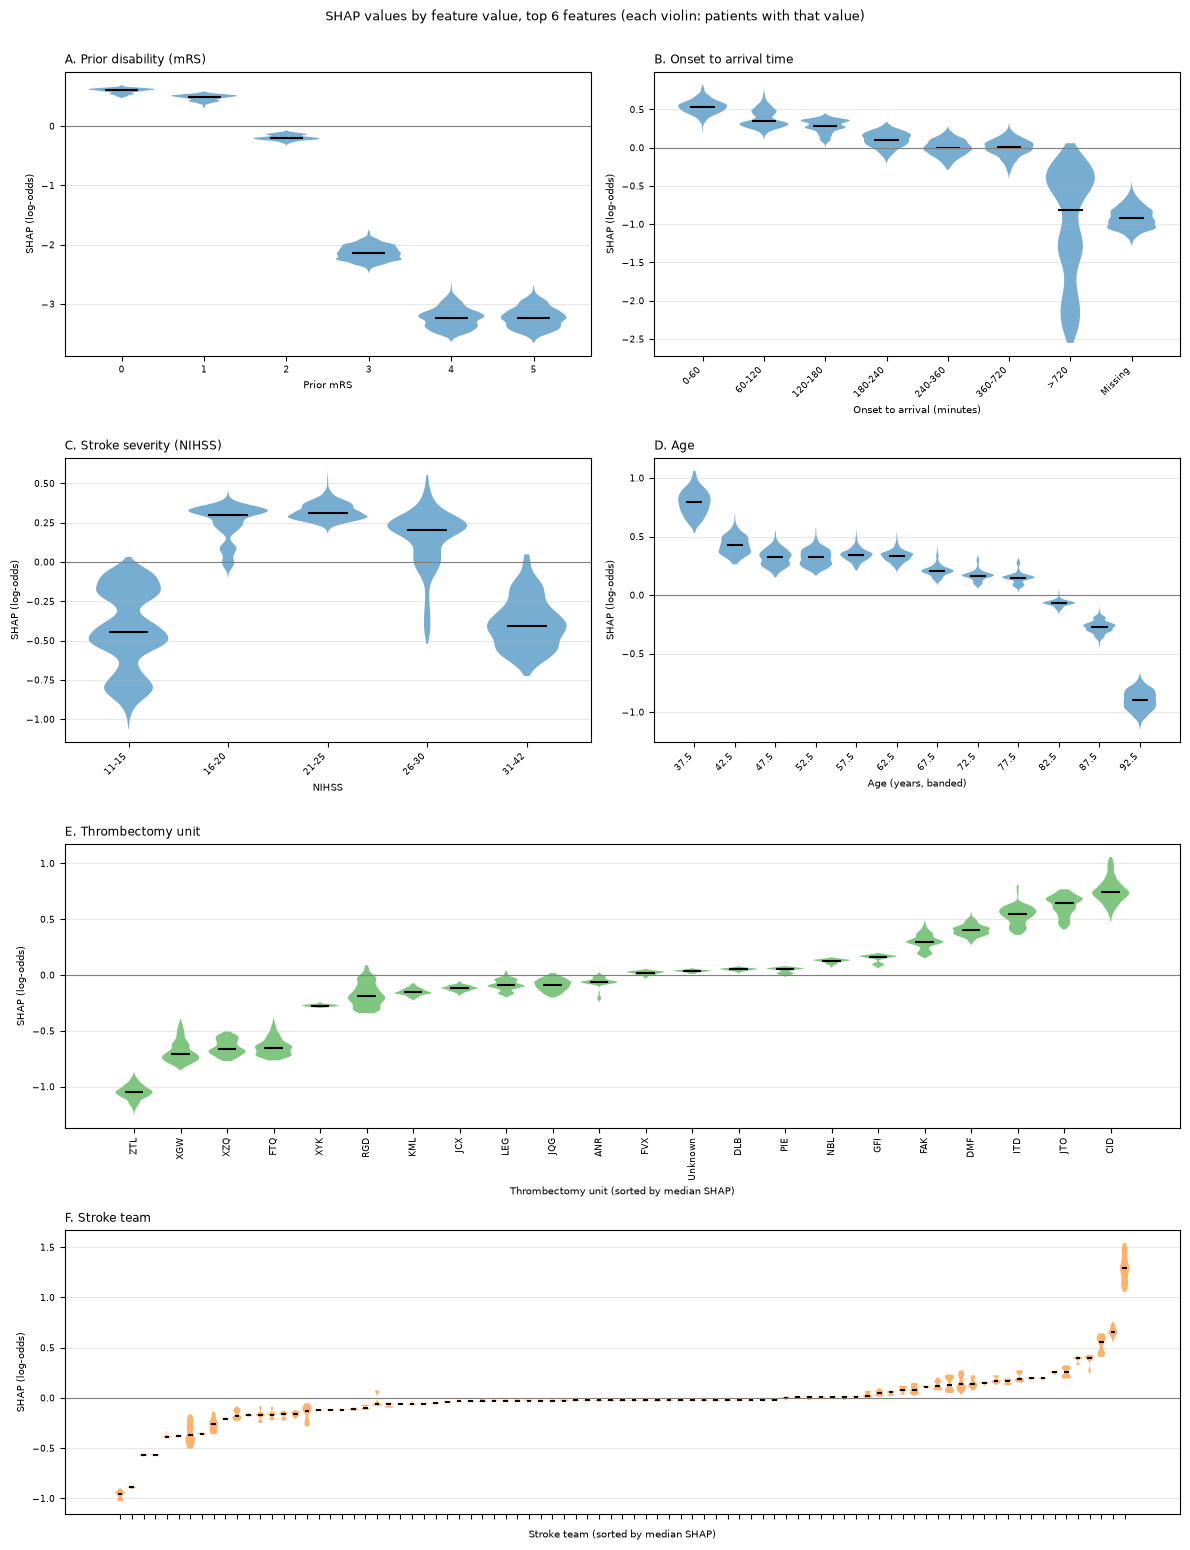

Prior disability (mRS): median SHAP by value
0    0.61
1    0.49
2   -0.20
3   -2.14
4   -3.24
5   -3.23 

Onset to arrival time: median SHAP by value
0-60       0.54
60-120     0.34
120-180    0.29
180-240    0.11
240-360   -0.01
360-720    0.00
>720      -0.82
Missing   -0.92 

Stroke severity (NIHSS): median SHAP by value
11-15   -0.45
16-20    0.30
21-25    0.31
26-30    0.20
31-42   -0.41 

Age: median SHAP by value
37.5    0.79
42.5    0.42
47.5    0.32
52.5    0.32
57.5    0.34
62.5    0.33
67.5    0.20
72.5    0.17
77.5    0.15
82.5   -0.07
87.5   -0.27
92.5   -0.90 

Thrombectomy unit: median SHAP from -1.05 (ZTL) to 0.74 (CID)
Stroke team: median SHAP from -0.96 (RVC) to 1.29 (LSO)


In [22]:
# SHAP violin plots for the 6 most important features (by mean |SHAP|): one violin per
# feature value, showing the spread of that feature's SHAP values across patients with that value
top_features = importance.sort_values(ascending=False).index[:6]

# Grouping of patients by feature value. Features with many values are banded; missing
# values form their own group. Team and unit use the patient's team or unit.
bands = {
    'onset_to_arrival_time': ([0, 60, 120, 180, 240, 360, 720, np.inf],
                              ['0-60', '60-120', '120-180', '180-240', '240-360', '360-720', '>720']),
    'stroke_severity': ([10, 15, 20, 25, 30, 42], ['11-15', '16-20', '21-25', '26-30', '31-42']),
}
x_labels = {
    'prior_disability': 'Prior mRS', 'onset_to_arrival_time': 'Onset to arrival (minutes)',
    'stroke_severity': 'NIHSS', 'age': 'Age (years, banded)',
    'Thrombectomy unit': 'Thrombectomy unit (sorted by median SHAP)',
    'Stroke team': 'Stroke team (sorted by median SHAP)'}

def feature_groups(feature):
    """Return a Series of group labels (one per patient) and the ordered list of groups."""
    if feature in ('Stroke team', 'Thrombectomy unit'):
        col = 'stroke_team' if feature == 'Stroke team' else 'MT_transfer_unit'
        groups = transfer_cohort[col].astype(object).fillna('Unknown')
        order = shap_df[feature].groupby(groups).median().sort_values().index.tolist()
        return groups, order
    values = transfer_cohort[feature]
    if feature in bands:
        edges, labels = bands[feature]
        groups = pd.cut(values, edges, labels=labels, right=True).astype(object)
        order = list(labels)
    else:
        groups = values.astype(object)
        order = sorted(values.dropna().unique())
    if values.isna().any():
        groups = groups.where(values.notna(), 'Missing')
        order = order + ['Missing']
    return groups, order

wide = [f for f in top_features if f in ('Stroke team', 'Thrombectomy unit')]
narrow = [f for f in top_features if f not in wide]
n_rows = int(np.ceil(len(narrow) / 2)) + len(wide)
fig = plt.figure(figsize=(12, 2.3 * 12 / 7 * n_rows))  # sized to fit one page of a paper
grid = fig.add_gridspec(n_rows, 2)
axes_for = {f: fig.add_subplot(grid[i // 2, i % 2]) for i, f in enumerate(narrow)}
for i, f in enumerate(wide):
    axes_for[f] = fig.add_subplot(grid[int(np.ceil(len(narrow) / 2)) + i, :])

colours = {'Stroke team': 'tab:orange', 'Thrombectomy unit': 'tab:green'}
violin_summary = {}
for letter, feature in zip('ABCDEF', top_features):
    ax = axes_for[feature]
    groups, order = feature_groups(feature)
    data = [shap_df.loc[groups == g, feature].values for g in order]
    keep = [i for i, d in enumerate(data) if len(d) >= 2]
    order, data = [order[i] for i in keep], [data[i] for i in keep]
    parts = ax.violinplot(data, positions=range(len(data)), widths=0.8, showmedians=True,
                          showextrema=False)
    for body in parts['bodies']:
        body.set_facecolor(colours.get(feature, 'tab:blue'))
        body.set_alpha(0.6)
    parts['cmedians'].set_color('k')
    ax.axhline(0, color='grey', linewidth=0.8)
    ax.set_xticks(range(len(order)))
    is_team = feature == 'Stroke team'
    rotation = 90 if feature == 'Thrombectomy unit' else 45 if len(order) > 6 or feature in bands else 0
    ax.set_xticklabels([] if is_team else [f'{g:g}' if isinstance(g, (int, float)) else g for g in order],
                       rotation=rotation, ha='right' if rotation == 45 else 'center', fontsize=6.5)
    ax.tick_params(axis='y', labelsize=6.5)
    ax.set_xlabel(x_labels.get(feature, feature_labels[feature]), fontsize=7.5)
    ax.set_ylabel('SHAP (log-odds)', fontsize=7.5)
    ax.set_title(f'{letter}. {feature_labels[feature]}', loc='left', fontsize=8.5)
    ax.grid(axis='y', alpha=0.3)
    violin_summary[feature] = pd.Series([np.median(d) for d in data], index=order)

fig.suptitle('SHAP values by feature value, top 6 features (each violin: patients with that value)', fontsize=9)
plt.tight_layout(rect=[0, 0, 1, 0.98])  # leave space for the overall title
plt.savefig('output/thrombectomy_transfer_xgb_shap_violins.png', dpi=300, bbox_inches='tight')
plt.show()

# Median SHAP for each value of the patient features
for feature in narrow:
    print(f'{feature_labels[feature]}: median SHAP by value')
    print(violin_summary[feature].round(2).to_string(), '\n')
for feature in wide:
    s = violin_summary[feature]
    print(f'{feature_labels[feature]}: median SHAP from {s.min():.2f} ({s.idxmin()}) to {s.max():.2f} ({s.idxmax()})')

**Results:**

* **A. Prior disability:** the strongest effect. The median contribution is +0.61 at prior mRS 0 and +0.49 at mRS 1, then falls to −0.20 at mRS 2, −2.14 at mRS 3 and about −3.2 at mRS 4–5. The violins are narrow, so the effect of prior mRS is much the same for every patient.
* **B. Onset to arrival:** thrombectomy is most likely for patients arriving within an hour of onset (median +0.54). The effect declines gradually to about zero for arrival 4–12 hours after onset, then drops sharply for arrival more than 12 hours after onset (median −0.82, with a wide spread) and for patients whose onset-to-arrival time is unknown (−0.92).
* **C. Stroke severity:** the effect is not a straight line. It is negative at NIHSS 11–15 (median −0.45), positive at 16–30 (+0.20 to +0.31) and negative again at 31–42 (−0.41). The wide, sometimes two-peaked violins show that the effect of NIHSS depends on other characteristics.
* **D. Age:** the effect falls steadily with age, from +0.79 in the youngest band (35–40 years) to +0.15 at 75–80, then becomes negative: −0.07 at 80–85, −0.27 at 85–90 and −0.90 at 90 and over.
* **E. Thrombectomy unit:** median unit effects range from −1.05 (ZTL) to +0.74 (CID). Each violin is narrow, so a unit's effect is similar for all its patients. Four units (ZTL, XGW, XZQ and FTQ) stand out with clearly lower odds of thrombectomy.
* **F. Stroke team:** once the unit is accounted for, most teams' effects are close to zero, with a few teams at either end (from −0.96 for RVC to +1.29 for LSO).

**What this cell does:** Asks what each team would do with **the same patients**.

- **How many:** each of the 18,296 patients is put through the model 87 times, each time as if they had first attended a different team (and so would be transferred to that team's thrombectomy unit). Averaging gives each team's predicted thrombectomy rate for an identical group of patients, removing differences in case mix. To keep this fair, each patient's predictions come from a version of the model built without that patient ("out-of-fold" prediction: patients are split into five groups and each group is predicted by a model built on the other four).
- **Which patients:** for each team and each of the 15 patient characteristics, an odds ratio is calculated: how much that team's predicted odds of thrombectomy change with the characteristic, across the same patients. For measurements (age, NIHSS, prior mRS, onset-to-arrival time) the odds ratio is per standard deviation (SD, a typical difference between two patients); for yes/no characteristics it is for present versus absent. If teams select patients differently, their odds ratios will differ. A Spearman correlation then tests whether teams that treat more patients weight characteristics differently, for example by also accepting older or more disabled patients.

The left panel plots each team's actual thrombectomy rate against the model's prediction for its own patients. The right panel puts both questions on one scale, relative to the average team: the orange row shows how much teams differ in the overall chance of thrombectomy for the same patients (how many), and each blue row shows how much teams' odds ratio for one characteristic differs from the average team's (which patients). Each dot is a team, and black bars span the 10th to 90th centile teams. The figure is saved to `output/xgb_same_patient_comparison.png`, and the table to `output/xgb_team_selection.csv`.

Out-of-fold ROC AUC (actual team): 0.841
Predicted rate for the same patients, 10th/50th/90th centile team: 10.4% / 17.9% / 25.7% (range 6.0% to 36.1%)
Odds multiplier relative to average team, 10th/90th centile: 0.50 / 1.85 (90th vs 10th: 3.7)
Spearman correlation, observed vs same-patient rate: 0.91
Observed vs same-patient rate: R² = 0.82, p = 4.6e-33 (slope 0.74)
Observed vs own-patient predicted rate: R² = 0.95, p < 0.001 (slope 0.86)
Relative to average team, 10th / 90th centile team:
  Team overall effect (same patients): 0.50 / 1.85
  Relative odds ratio: Age (per SD): 0.95 / 1.06
  Relative odds ratio: Male: 0.95 / 1.05
  Relative odds ratio: NIHSS (per SD): 0.97 / 1.03
  Relative odds ratio: Prior mRS (per SD): 0.95 / 1.05
  Relative odds ratio: Onset to arrival time (per SD): 0.98 / 1.02
  Relative odds ratio: Onset time known: 0.88 / 1.13
  Relative odds ratio: Precise onset time known: 0.95 / 1.08
  Relative odds ratio: Onset during sleep: 0.94 / 1.06
  Relative odds ratio

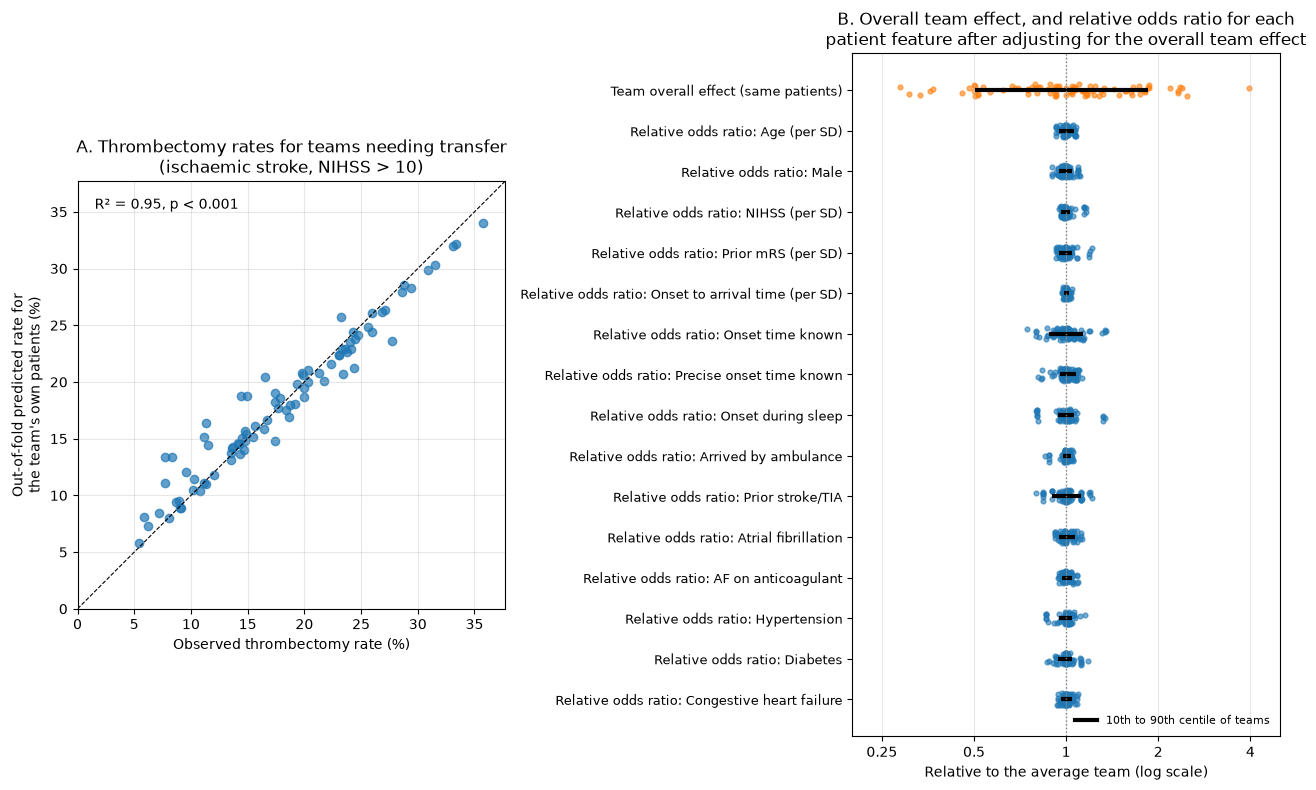

,Unit,Mean (or % present),% missing,"OR, all teams","OR, 10th centile team","OR, 90th centile team","OR, min","OR, max",Spearman rho vs team log-odds,p
Characteristic,,,,,,,,,,
Age (per SD),1 SD = 12.6,77.679,0.000,0.410,0.390,0.436,0.380,0.443,-0.195,0.070
Male,present vs absent,46.072,0.016,2.045,1.945,2.140,1.838,2.265,0.066,0.545
NIHSS (per SD),1 SD = 5.5,17.847,0.000,1.099,1.061,1.135,1.043,1.281,0.235,0.029
Prior mRS (per SD),1 SD = 1.6,1.598,0.000,0.193,0.182,0.202,0.179,0.234,-0.303,0.004
Onset to arrival time (per SD),1 SD = 1813.9,467.566,18.305,0.753,0.740,0.770,0.729,0.785,0.001,0.995
Onset time known,present vs absent,81.695,0.000,3.510,3.096,3.976,2.618,4.725,-0.011,0.923
Precise onset time known,present vs absent,36.456,0.000,3.274,3.124,3.533,2.650,3.691,0.106,0.327
Onset during sleep,present vs absent,12.035,0.000,1.078,1.017,1.142,0.860,1.448,-0.030,0.782
Arrived by ambulance,present vs absent,91.525,0.361,0.829,0.811,0.859,0.709,0.876,-0.061,0.575


In [23]:
# Predict the same cohort of patients at every team, using out-of-fold predictions:
# patients are split into 5 folds (stratified by team), and each patient's predictions
# for every team come from a model trained only on the other 4 folds.
oof_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
team_names = [col.replace('team_', '') for col in team_cols]
# Thrombectomy unit column for each team (None if the team's unit is not known)
team_unit = transfer_cohort.groupby('stroke_team')['MT_transfer_unit'].first()
team_unit_col = {col: (None if pd.isna(team_unit[col.replace('team_', '')])
                       else f"unit_{team_unit[col.replace('team_', '')]}") for col in team_cols}
same_patient = pd.DataFrame(np.nan, index=X.index, columns=team_names)
oof_pred = np.full(len(X), np.nan)
for fold, (train_idx, test_idx) in enumerate(
        oof_cv.split(X, transfer_cohort['stroke_team'].astype(str))):
    fold_model = xgb.XGBClassifier(**best_params).fit(X.iloc[train_idx], y[train_idx])
    X_fold = X.iloc[test_idx]
    oof_pred[test_idx] = fold_model.predict_proba(X_fold)[:, 1]
    for j, col in enumerate(team_cols):
        X_team = X_fold.copy()
        X_team[team_cols] = 0.0
        X_team[col] = 1.0
        # Give the patients the thrombectomy unit of the team they are assigned to
        X_team[unit_cols] = 0.0
        if team_unit_col[col] is not None:
            X_team[team_unit_col[col]] = 1.0
        same_patient.iloc[test_idx, j] = fold_model.predict_proba(X_team)[:, 1]
assert not same_patient.isna().any().any()
print(f'Out-of-fold ROC AUC (actual team): {roc_auc_score(y, oof_pred):.3f}')
same_patient_logit = np.log(same_patient / (1 - same_patient))

team_rate_same = same_patient.mean()
team_logit_same = same_patient_logit.mean()
observed_rate = transfer_cohort.groupby('stroke_team')['thrombectomy'].mean().loc[team_rate_same.index]

q = team_rate_same.quantile([0.1, 0.5, 0.9]) * 100
print(f'Predicted rate for the same patients, 10th/50th/90th centile team: '
      f'{q[0.1]:.1f}% / {q[0.5]:.1f}% / {q[0.9]:.1f}% '
      f'(range {team_rate_same.min()*100:.1f}% to {team_rate_same.max()*100:.1f}%)')
centred = team_logit_same - team_logit_same.mean()
print(f'Odds multiplier relative to average team, 10th/90th centile: '
      f'{np.exp(centred.quantile(0.1)):.2f} / {np.exp(centred.quantile(0.9)):.2f} '
      f'(90th vs 10th: {np.exp(centred.quantile(0.9) - centred.quantile(0.1)):.1f})')
print(f'Spearman correlation, observed vs same-patient rate: '
      f'{stats.spearmanr(observed_rate, team_rate_same)[0]:.2f}')

# Per-team odds ratio for each of the 15 patient features in the model, using each feature's
# actual values (no cut-points): the slope of each team's predicted log-odds on the feature
# across the same patients. Continuous features are standardised, giving the odds ratio per
# 1 SD; 0/1 features give the odds ratio for present vs absent. Missing values are excluded
# for that feature only.
feature_names = {
    'age': 'Age', 'male': 'Male', 'stroke_severity': 'NIHSS',
    'prior_disability': 'Prior mRS', 'onset_to_arrival_time': 'Onset to arrival time',
    'onset_known': 'Onset time known', 'precise_onset_known': 'Precise onset time known',
    'onset_during_sleep': 'Onset during sleep', 'arrive_by_ambulance': 'Arrived by ambulance',
    'prior_stroke_tia': 'Prior stroke/TIA', 'atrial_fibrillation': 'Atrial fibrillation',
    'afib_anticoagulant': 'AF on anticoagulant', 'hypertension': 'Hypertension',
    'diabetes': 'Diabetes', 'congestive_heart_failure': 'Congestive heart failure'}
assert set(feature_names) == set(patient_features)

selection_rows, team_odds_ratios = [], {}
for feature, label in feature_names.items():
    x = transfer_cohort[feature].astype(float)
    present = x.notna().values
    x = x[present]
    binary = set(x.unique()) <= {0.0, 1.0}
    name = label if binary else f'{label} (per SD)'
    z = x if binary else (x - x.mean()) / x.std()
    z = (z - z.mean()).values
    slope = same_patient_logit[present].mul(z, axis=0).sum() / (z ** 2).sum()
    team_odds_ratios[name] = np.exp(slope)
    rho, p = stats.spearmanr(team_logit_same, slope.loc[team_logit_same.index])
    selection_rows.append({
        'Characteristic': name,
        'Unit': 'present vs absent' if binary else f'1 SD = {x.std():.1f}',
        'Mean (or % present)': 100 * x.mean() if binary else x.mean(),
        '% missing': 100 * (1 - present.mean()),
        'OR, all teams': np.exp(slope.mean()),
        'OR, 10th centile team': np.exp(slope.quantile(0.1)),
        'OR, 90th centile team': np.exp(slope.quantile(0.9)),
        'OR, min': np.exp(slope.min()), 'OR, max': np.exp(slope.max()),
        'Spearman rho vs team log-odds': rho, 'p': p})
team_selection = pd.DataFrame(selection_rows).set_index('Characteristic')
team_selection.round(3).to_csv('output/xgb_team_selection.csv')

# Same-patient rates vs observed rates (reported, not plotted)
lr_same = stats.linregress(observed_rate, team_rate_same)
print(f'Observed vs same-patient rate: R² = {lr_same.rvalue**2:.2f}, '
      f'p = {lr_same.pvalue:.2g} (slope {lr_same.slope:.2f})')

# Panel A: each team's own patients, mean out-of-fold prediction (actual team) vs observed rate
own_rate = (pd.Series(oof_pred, index=X.index)
            .groupby(transfer_cohort['stroke_team']).mean().loc[team_rate_same.index])

fig, axes = plt.subplots(1, 2, figsize=(13, 8))
axes[0].set_box_aspect(1)  # keep panel A square while panel B is taller
ax = axes[0]
ax.scatter(observed_rate * 100, own_rate * 100, color='tab:blue', alpha=0.7)
lim = [0, max(observed_rate.max(), own_rate.max()) * 100 + 2]
ax.plot(lim, lim, 'k--', linewidth=0.8)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel('Observed thrombectomy rate (%)')
ax.set_ylabel("Out-of-fold predicted rate for\nthe team's own patients (%)")
ax.set_title('A. Thrombectomy rates for teams needing transfer\n(ischaemic stroke, NIHSS > 10)')
ax.grid(alpha=0.3)
# Linear fit of predicted (own patients) vs observed team rates
lr = stats.linregress(observed_rate, own_rate)
p_text = 'p < 0.001' if lr.pvalue < 0.001 else f'p = {lr.pvalue:.3f}'
print(f'Observed vs own-patient predicted rate: R² = {lr.rvalue**2:.2f}, {p_text} (slope {lr.slope:.2f})')
ax.text(0.04, 0.96, f'R² = {lr.rvalue**2:.2f}, {p_text}', transform=ax.transAxes, va='top')
# Panel B: how much teams differ in HOW MANY patients (overall team effect) versus
# WHICH patients (team odds ratio for each characteristic), both relative to the
# average team on the same log scale
ax = axes[1]
relative = {'Team overall effect (same patients)': np.exp(centred)}
for name, ors in team_odds_ratios.items():
    log_ors = np.log(ors)
    relative[f'Relative odds ratio: {name}'] = np.exp(log_ors - log_ors.mean())
rng = np.random.default_rng(42)
n_rows = len(relative)
print('Relative to average team, 10th / 90th centile team:')
for i, (name, vals) in enumerate(relative.items()):
    y_pos = n_rows - 1 - i
    colour = 'tab:orange' if i == 0 else 'tab:blue'
    ax.scatter(vals, y_pos + rng.uniform(-0.15, 0.15, len(vals)), s=12, alpha=0.6, color=colour)
    lo, hi = np.quantile(vals, [0.1, 0.9])
    ax.plot([lo, hi], [y_pos, y_pos], color='k', linewidth=3, solid_capstyle='butt')
    print(f"  {name.replace(chr(10), ' ')}: {lo:.2f} / {hi:.2f}")
ax.set_xscale('log')
ticks = [0.25, 0.5, 1, 2, 4]
ax.set_xticks(ticks)
ax.set_xticklabels([str(t) for t in ticks])
ax.set_xlim(0.2, 5)
ax.minorticks_off()
ax.set_yticks(range(n_rows))
ax.set_yticklabels(list(relative)[::-1], fontsize=9)
ax.axvline(1, color='grey', linestyle=':', linewidth=1)
ax.set_xlabel('Relative to the average team (log scale)')
ax.set_title('B. Overall team effect, and relative odds ratio for each\n'
             'patient feature after adjusting for the overall team effect')
ax.plot([], [], color='k', linewidth=3, label='10th to 90th centile of teams')
ax.legend(loc='lower right', fontsize=8, frameon=False)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('output/xgb_same_patient_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

team_selection.round(3)

**Results:** The model reproduces each team's actual thrombectomy rate closely (R² = 0.95, p < 0.001), with a slope of 0.86: the most extreme teams are pulled slightly towards the average, as expected when predicting patients the model was not built on. The out-of-fold ROC AUC is 0.841, similar to the test set (0.834).

**How many:** given the same 18,296 patients, predicted thrombectomy rates still vary widely between teams: 10.4% at the 10th centile team, 17.9% at the median and 25.7% at the 90th centile (range 6.0% to 36.1%). For the same patient, the odds of thrombectomy are about 3.7 times higher at the 90th centile team than at the 10th (0.50 and 1.85 times the average team). These same-patient rates closely follow the teams' actual rates (R² = 0.82, p < 0.001; Spearman ρ = 0.91), so differences in case mix explain little of the variation between teams.

**Which patients:** teams weight patient characteristics similarly. While the orange row spans 0.50 to 1.85 between the 10th and 90th centile teams, every blue row stays within about 13% of the average team. For example, the odds ratios at the 10th and 90th centile teams are 0.39 and 0.44 per SD of age (12.6 years), 0.18 and 0.20 per SD of prior mRS (1.6 points), 1.06 and 1.14 per SD of NIHSS (5.5 points), and 3.10 and 3.98 for a known onset time. Teams that treat more patients do not extend thrombectomy to more marginal patients. If anything the reverse: higher-rate teams are slightly more selective on prior stroke/TIA (ρ = −0.32, p = 0.003), prior mRS (ρ = −0.30, p = 0.004), AF on anticoagulant (ρ = −0.29, p = 0.006), congestive heart failure (ρ = −0.27, p = 0.013) and atrial fibrillation (ρ = −0.23, p = 0.034), and give slightly more weight to higher NIHSS (ρ = 0.23, p = 0.029). These associations are weak, and with 15 characteristics tested some may arise by chance: only prior stroke/TIA remains significant after Bonferroni correction (a stricter threshold, p < 0.0033, that allows for 15 tests), with prior mRS just missing it (p = 0.004). The other nine characteristics show no association (p ≥ 0.07).

These odds ratios also reflect characteristics that tend to go together (for example, older patients more often have prior disability). Onset-to-arrival time is very skewed (mean 468 minutes, SD 1,814 minutes) and is missing for 18% of patients, who are left out of that row only.

**What this cell does:** For teams with at least 20 thrombectomy patients, describes the patients each team actually sent for thrombectomy (proportion aged 80 or over, with prior mRS 2 or more, and arriving more than 4 hours after onset or with an unknown onset time, and the average NIHSS). Spearman correlation is used to test whether teams with higher thrombectomy rates send different types of patients.

In [24]:
treated_profile = transfer_cohort[transfer_cohort['thrombectomy'] == 1].groupby('team').agg(
    n_thrombectomy=('thrombectomy', 'size'), age80=('age80', 'mean'), mrs2=('mrs2', 'mean'),
    late=('late', 'mean'), mean_nihss=('stroke_severity', 'mean'))
team_profile = team_rates.join(treated_profile)
team_profile = team_profile[team_profile['n_thrombectomy'] >= 20]

print(f'Teams with at least 20 thrombectomy patients: {len(team_profile)}')
for col in ['age80', 'mrs2', 'late', 'mean_nihss']:
    rho, p = stats.spearmanr(team_profile['thrombectomy_rate'], team_profile[col])
    print(f'Thrombectomy rate vs {col}: rho = {rho:.2f}, p = {p:.2g}')
team_profile[['thrombectomy_rate', 'age80', 'mrs2', 'late', 'mean_nihss']].describe(
    percentiles=[0.1, 0.5, 0.9]).round(3).T[['10%', '50%', '90%']]

Teams with at least 20 thrombectomy patients: 66
Thrombectomy rate vs age80: rho = 0.05, p = 0.67
Thrombectomy rate vs mrs2: rho = 0.04, p = 0.74
Thrombectomy rate vs late: rho = 0.13, p = 0.3
Thrombectomy rate vs mean_nihss: rho = -0.19, p = 0.13


,10%,50%,90%
thrombectomy_rate,0.117,0.196,0.287
age80,0.204,0.313,0.417
mrs2,0.031,0.108,0.207
late,0.164,0.267,0.427
mean_nihss,16.908,18.295,19.921


**Results:** Across 66 teams, the patients sent for thrombectomy vary. Aged 80 or over: 20–42% (10th to 90th centile team); prior mRS 2 or more: 3–21%; arrival more than 4 hours after onset or unknown: 16–43%. Teams with higher thrombectomy rates do not send older, more disabled or later-arriving patients: none of the correlations is statistically significant (ρ between −0.19 and 0.13).

### Summary: team differences in selection for thrombectomy transfer

- The main difference between non-thrombectomy teams is **how many** patients go on to thrombectomy, not **which** ones. Given the same 18,296 patients (ischaemic stroke, NIHSS > 10), the model predicts thrombectomy rates of 10.4% at the 10th centile team and 25.7% at the 90th centile team: for the same patient, the odds are about 3.7 times higher. Same-patient rates closely follow actual rates (R² = 0.82), so case mix explains little of the variation.
- **Much of the team effect is shared by teams that transfer to the same thrombectomy unit.** In the SHAP analysis the thrombectomy unit (mean |SHAP| 0.30) is more important than the stroke team (0.16), ranking after prior disability, onset-to-arrival time, stroke severity and age. A model with patient characteristics and unit but no team predicts almost as well (ROC AUC 0.832) as one that also includes team (0.834); patient characteristics alone give 0.814.
- Teams weight all 15 patient characteristics similarly (each team's odds ratio for every characteristic is within about 13% of the average team's), and teams that transfer more do not extend thrombectomy to more marginal patients. If anything, higher-rate teams are slightly more selective on comorbidity and prior disability; only the association with prior stroke/TIA survives correction for testing 15 characteristics.

**Caveats:**

- The unit effect may reflect the receiving unit's acceptance practice or capacity, shared referral pathways, or geography (distance to the unit), which this model cannot separate. The remaining team effect may reflect access to CT angiography and the team's own referral decisions.
- Brain imaging results were not included (large vessel occlusion is missing for 38% of patients, ASPECTS for 63%), so selection based on imaging is absorbed into the team and unit effects.
- The outcome is completed thrombectomy, not referral for it.
- The model deliberately avoids fitting small groups too closely and uses simple trees, so small team-specific differences in selection, or differences confined to small teams, may not be detected.

## Thrombectomy units and variation between referring teams

Which stroke team a patient first attends strongly affects whether they are transferred for thrombectomy. Each stroke team transfers to one thrombectomy unit (recorded in the data as `MT_transfer_unit`). These cells look at how teams' thrombectomy rates relate to the thrombectomy unit they transfer to, and to that unit's thrombectomy rate for its own patients.

**Note:** these cells use all patients with ischaemic stroke and NIHSS > 10 (2024–2025), not only those who received thrombectomy.

**What this cell does:** Selects patients who first attended a non-thrombectomy hospital and whose team has a recorded thrombectomy unit. Checks that each stroke team transfers to a single thrombectomy unit, and counts the patients, teams and units, the proportion receiving thrombectomy, and the proportion of those thrombectomies with a transfer recorded.

In [25]:
# Patients who first attended a non-thrombectomy centre, with a known thrombectomy unit
transfer_data = data_filtered[
    (data_filtered['thrombectomy_centre'] == 0) & (data_filtered['MT_transfer_unit'].notna())
].copy()

# Check each stroke team maps to a single thrombectomy unit
units_per_team = transfer_data.groupby('stroke_team')['MT_transfer_unit'].nunique()
print(f"Teams with more than one MT_transfer_unit: {(units_per_team > 1).sum()}")

print(f"Patients: {len(transfer_data):,}")
print(f"Stroke teams: {transfer_data['stroke_team'].nunique()}")
print(f"Thrombectomy units: {transfer_data['MT_transfer_unit'].nunique()}")
print(f"Proportion receiving thrombectomy: {transfer_data['thrombectomy'].mean():.3f}")
print(f"Proportion of thrombectomies with transfer recorded: "
      f"{transfer_data.loc[transfer_data['thrombectomy'] == 1, 'transfer_used'].mean():.3f}")

Teams with more than one MT_transfer_unit: 0
Patients: 18,189
Stroke teams: 86
Thrombectomy units: 21
Proportion receiving thrombectomy: 0.178
Proportion of thrombectomies with transfer recorded: 0.957


**Results:** 18,189 patients from 86 stroke teams, transferring to 21 thrombectomy units (about 4 teams per unit). Every team transfers to a single unit, so the unit is a property of the team, not of the individual patient. 17.8% received thrombectomy, and 95.7% of these had a transfer recorded, so for these patients thrombectomy is effectively transfer for thrombectomy.

**What this cell does:** Calculates the proportion receiving thrombectomy for each stroke team (`team_rates`) and each thrombectomy unit (`unit_rates`, all patients from that unit's teams pooled), and summarises the spread of each.

In [26]:
# Thrombectomy (transfer) rate per stroke team and per thrombectomy unit
team_rates = transfer_data.groupby('stroke_team').agg(
    unit=('MT_transfer_unit', 'first'),
    rate=('thrombectomy', 'mean'),
    n=('thrombectomy', 'size'))

unit_rates = transfer_data.groupby('MT_transfer_unit').agg(
    rate=('thrombectomy', 'mean'),
    n=('thrombectomy', 'size'),
    teams=('stroke_team', 'nunique'))

quantiles = [0, 0.25, 0.5, 0.75, 1]
summary_rates = pd.DataFrame({
    'Stroke teams (%)': team_rates['rate'].quantile(quantiles) * 100,
    'Thrombectomy units (%)': unit_rates['rate'].quantile(quantiles) * 100,
}, index=quantiles).rename(index={0: 'min', 0.25: '25%', 0.5: 'median', 0.75: '75%', 1: 'max'})
summary_rates.round(1)

,Stroke teams (%),Thrombectomy units (%)
min,5.5,6.7
25%,12.4,13.5
median,17.6,16.6
75%,23.5,22.5
max,35.7,28.0


**Results:** Team rates range from 5.5% to 35.7% (IQR 12.4–23.5%). Unit rates are almost as spread out: 6.7% to 28.0% (IQR 13.5–22.5%). Much of the variation between teams is therefore also present between units.

### Team thrombectomy rates grouped by thrombectomy unit

**What this cell does:** Plots, for each thrombectomy unit (one row each, sorted by the thrombectomy rate of the unit's own patients), the thrombectomy rate of each stroke team that transfers to it (blue) and of the unit's own patients, who first attended the thrombectomy unit (red). Circle area is proportional to the number of thrombectomies. The light blue band shows the range (lowest to highest) of the transferring teams' rates for each unit. The black tick is the rate for all patients of the unit's transferring teams, the grey dashed line is the rate for all patients first attending a non-thrombectomy centre, and the red dashed line is the rate for all patients who first attended any thrombectomy unit (all 25 units). The figure is saved to `./output/mt_transfer_by_team_and_unit.jpg`.

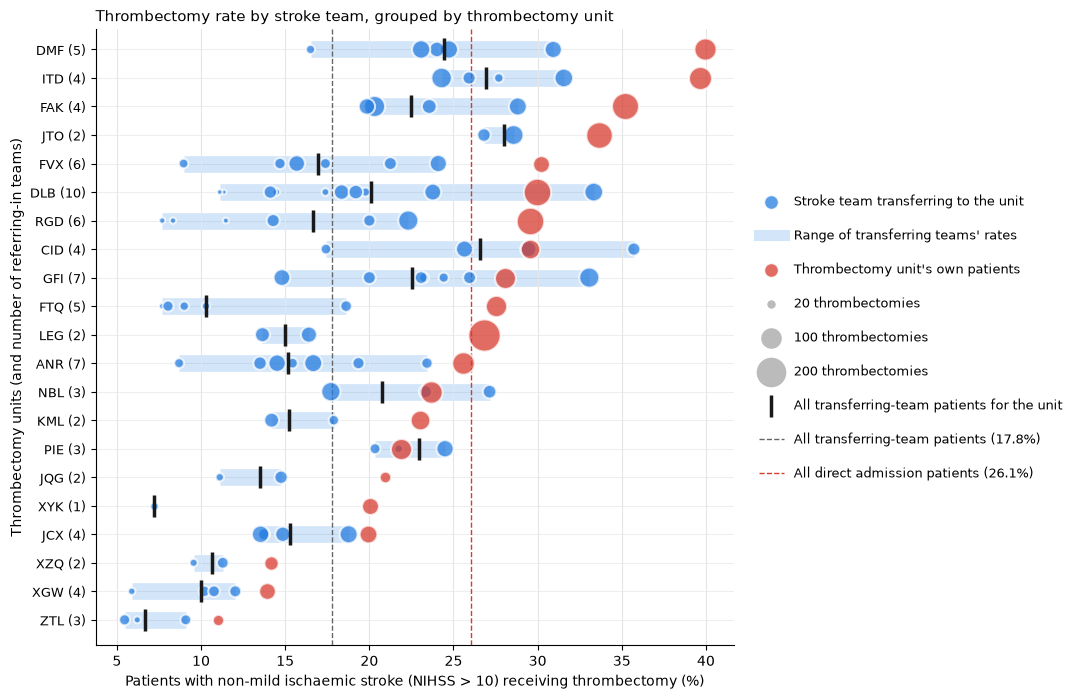

In [27]:
# Dot plot: one row per thrombectomy unit.
# Blue = stroke teams that transfer to the unit; red = the unit's own patients (first attended the unit).
# Circle area is proportional to the number of thrombectomies (procedures).
# Light blue band = range (lowest to highest) of the transferring teams' rates for each unit.
from matplotlib.lines import Line2D

team_rates['procedures'] = transfer_data.groupby('stroke_team')['thrombectomy'].sum()
unit_own = data_filtered[data_filtered['thrombectomy_centre'] == 1].groupby('stroke_team')[
    'thrombectomy'].agg(rate='mean', procedures='sum', n='size')

# Sort rows by the thrombectomy rate of each unit's own patients
order = unit_own.loc[unit_rates.index, 'rate'].sort_values().index
team_range = team_rates.groupby('unit')['rate'].agg(['min', 'max'])
blue, red, ink, grey = '#257de0', '#d63b2f', '#191919', '#666666'
size_per_procedure = 2.5  # marker area (points^2) per thrombectomy

fig, ax = plt.subplots(figsize=(11, 8))
for i, unit in enumerate(order):
    teams = team_rates[team_rates['unit'] == unit]
    ax.hlines(i, team_range.loc[unit, 'min'] * 100, team_range.loc[unit, 'max'] * 100,
              color=blue, alpha=0.2, linewidth=12, zorder=1)
    ax.scatter(teams['rate'] * 100, np.full(len(teams), i), s=teams['procedures'] * size_per_procedure,
               color=blue, alpha=0.75, edgecolor='white', linewidth=1.5, zorder=3)
    if unit in unit_own.index:
        ax.scatter(unit_own.loc[unit, 'rate'] * 100, i,
                   s=unit_own.loc[unit, 'procedures'] * size_per_procedure,
                   color=red, alpha=0.75, edgecolor='white', linewidth=1.5, zorder=3)
    ax.scatter(unit_rates.loc[unit, 'rate'] * 100, i, marker='|', s=250,
               color=ink, linewidth=2.5, zorder=4)

overall = transfer_data['thrombectomy'].mean() * 100
ax.axvline(overall, color=grey, linestyle='--', linewidth=1, zorder=1)

# All patients admitted directly to a thrombectomy unit (first attended any thrombectomy centre)
direct = data_filtered.loc[data_filtered['thrombectomy_centre'] == 1, 'thrombectomy'].mean() * 100
ax.axvline(direct, color=red, linestyle='--', linewidth=1, zorder=1)

ax.set_yticks(range(len(order)))
ax.set_yticklabels([f"{u} ({unit_rates.loc[u, 'teams']})" for u in order], fontsize=9)
ax.set_xlabel('Patients with non-mild ischaemic stroke (NIHSS > 10) receiving thrombectomy (%)')
ax.set_ylabel('Thrombectomy units (and number of referring-in teams)')
ax.set_ylim(-0.9, len(order) - 0.3)
ax.grid(axis='x', color='#e5e5e5', linewidth=0.8, zorder=0)
# Faint horizontal line along each thrombectomy unit's row
for row in range(len(order)):
    ax.axhline(row, color='#eeeeee', linewidth=0.8, zorder=0)
ax.spines[['top', 'right']].set_visible(False)

# Legend: colours, circle sizes (in procedures) and the unit marker
handles = [
    ax.scatter([], [], s=40 * size_per_procedure, color=blue, alpha=0.75, edgecolor='white',
               label='Stroke team transferring to the unit'),
    ax.scatter([], [], s=40 * size_per_procedure, color=red, alpha=0.75, edgecolor='white',
               label="Thrombectomy unit's own patients"),
]
handles.insert(1, Line2D([], [], color=blue, alpha=0.2, linewidth=8,
                         label="Range of transferring teams' rates"))
handles += [ax.scatter([], [], s=p * size_per_procedure, color='#bbbbbb', edgecolor='white',
                       label=f'{p} thrombectomies') for p in (20, 100, 200)]
handles.append(ax.scatter([], [], marker='|', s=250, color=ink, linewidth=2.5,
                          label='All transferring-team patients for the unit'))
handles.append(Line2D([], [], color=grey, linestyle='--', linewidth=1,
                      label=f'All transferring-team patients ({overall:.1f}%)'))
handles.append(Line2D([], [], color=red, linestyle='--', linewidth=1,
                      label=f'All direct admission patients ({direct:.1f}%)'))
ax.legend(handles=handles, loc='center left', bbox_to_anchor=(1.01, 0.5), frameon=False,
          fontsize=9, labelspacing=1.6, borderpad=1)

ax.set_title('Thrombectomy rate by stroke team, grouped by thrombectomy unit', loc='left', fontsize=11)
fig.subplots_adjust(left=0.14, right=0.72)  # leave room for the legend on the right
plt.savefig('./output/mt_transfer_by_team_and_unit.jpg', dpi=300, bbox_inches='tight')
plt.show()

**Results:** Transferring teams cluster around their unit's rate (black tick), which ranges from 6.7% to 28.0% across units. Rows are sorted by the rate for the unit's own patients (11.0% to 39.9%); the transferring teams' rate broadly rises with it, but not strictly in order. Teams transferring to the same unit still differ, but by less than teams overall.

Overall, 26.1% of patients admitted directly to a thrombectomy unit received thrombectomy (n = 8,851), compared with 17.8% of patients of transferring teams. Each unit's own patients (red) are more likely to receive thrombectomy than patients of its transferring teams (higher in 20 of 21 units, by a median of 7.8 percentage points; the units' own rates range from 11.0% to 39.9%). A unit's own rate also tracks its transferring teams' rate closely (r = 0.78, Spearman 0.76, across 21 units): units that treat more of their own patients also accept more transfers. This suggests part of the unit effect reflects the unit's own threshold for thrombectomy, not only geography, although case mix of directly admitted patients may differ.

The rates of individual transferring teams vary within each unit (blue band), with a median range of 8.1 percentage points between a unit's lowest and highest team. Ranges are wider where more teams share a unit: all eight units with a range over 10 points have 4 to 10 teams, the widest being DLB (10 teams, 11.1% to 33.3%). XYK has a single transferring team, so it has no range. In 16 of 21 units, the unit's own rate is higher than that of every one of its transferring teams.

### Referring teams' rates and the thrombectomy unit's own rate

**What this cell does:** For each referring stroke team (one point each, 86 teams), plots the thrombectomy rate for the own patients of the thrombectomy unit the team transfers to (x-axis) against the team's own thrombectomy rate (y-axis). Teams transferring to the same unit share an x value. Circle area is proportional to the team's number of patients. Reports the correlation between the two rates (Pearson, and Spearman, which uses ranks), and fits a straight line across all teams, shown with its 95% confidence band (the range within which the true line is likely to lie). The dashed line of equality marks where a team's rate would equal its unit's own rate. The figure is saved to `./output/mt_unit_own_vs_transfer_in.jpg`.

Referring stroke teams: 86; thrombectomy units: 21
Pearson r = 0.57 (p = 1e-08); Spearman rho = 0.52 (p = 3e-07)
Slope: 0.58 (95% CI 0.40 to 0.76); R2 = 0.32


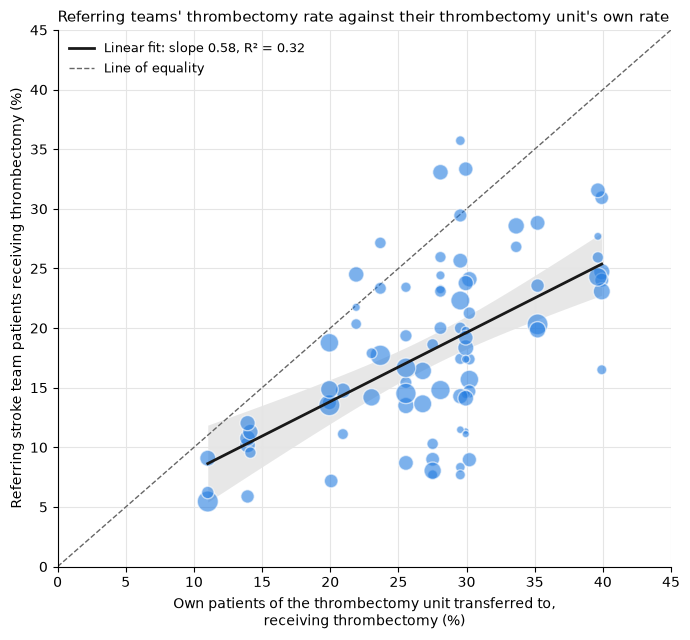

In [28]:
from scipy import stats
import statsmodels.api as sm

# One point per referring stroke team: rate for the own patients of the thrombectomy unit the team
# transfers to (x) against the team's own thrombectomy rate (y)
team_compare = team_rates[['unit', 'rate', 'n']].join(
    unit_own['rate'].rename('unit_own_rate'), on='unit')
x, y = team_compare['unit_own_rate'] * 100, team_compare['rate'] * 100

r, p = stats.pearsonr(x, y)
rho, p_rho = stats.spearmanr(x, y)
fit = sm.OLS(y, sm.add_constant(x)).fit()
slope, (slope_lo, slope_hi) = fit.params.iloc[1], fit.conf_int().iloc[1]
print(f"Referring stroke teams: {len(team_compare)}; thrombectomy units: {team_compare['unit'].nunique()}")
print(f"Pearson r = {r:.2f} (p = {p:.1g}); Spearman rho = {rho:.2f} (p = {p_rho:.1g})")
print(f"Slope: {slope:.2f} (95% CI {slope_lo:.2f} to {slope_hi:.2f}); R2 = {fit.rsquared:.2f}")

# Plot: one circle per referring team (area proportional to its patients), linear fit across
# all teams with 95% CI, and line of equality
blue, ink, grey = '#257de0', '#191919', '#666666'
fig, ax = plt.subplots(figsize=(7, 6.5))
ax.scatter(x, y, s=team_compare['n'] / 2, color=blue, alpha=0.6,
           edgecolor='white', linewidth=1, zorder=3)

x_line = np.linspace(x.min(), x.max(), 100)
pred = fit.get_prediction(sm.add_constant(x_line)).summary_frame(alpha=0.05)
ax.fill_between(x_line, pred['mean_ci_lower'], pred['mean_ci_upper'], color=ink, alpha=0.1,
                linewidth=0, zorder=1)
ax.plot(x_line, pred['mean'], color=ink, linewidth=2, zorder=4,
        label=f'Linear fit: slope {slope:.2f}, R² = {fit.rsquared:.2f}')
lims = [0, 45]
ax.plot(lims, lims, color=grey, linestyle='--', linewidth=1, zorder=2, label='Line of equality')

ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Own patients of the thrombectomy unit transferred to,\nreceiving thrombectomy (%)")
ax.set_ylabel('Referring stroke team patients receiving thrombectomy (%)')
ax.grid(color='#e5e5e5', linewidth=0.8, zorder=0)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(loc='upper left', frameon=False, fontsize=9)
ax.set_title("Referring teams' thrombectomy rate against their thrombectomy unit's own rate",
             loc='left', fontsize=11)
plt.tight_layout()
plt.savefig('./output/mt_unit_own_vs_transfer_in.jpg', dpi=300)
plt.show()

**Results:** Across 86 referring stroke teams (21 thrombectomy units), a team's thrombectomy rate is correlated with the rate for its thrombectomy unit's own patients (Pearson r = 0.57, Spearman ρ = 0.52, both p < 0.001; R² = 0.32). The slope is 0.58 (95% CI 0.40 to 0.76): each 1 percentage point higher rate for the unit's own patients goes with about 0.6 points higher rate for its referring teams. Only 5 of the 86 teams lie above the line of equality, as referring teams' patients are generally less likely to receive thrombectomy than the unit's own patients.

Teams referring to the same unit still vary around the fitted line, so the unit's own rate explains about a third of the variation between individual teams. This suggests that part of the variation between teams in transfer for thrombectomy reflects the threshold for thrombectomy at the unit they transfer to, not only geography. The comparison is not adjusted for case mix, which may differ between directly admitted and referring-in patients.

## Conclusions

- **Thrombectomy use:** 20.5% of patients with ischaemic stroke and NIHSS > 10 received thrombectomy in 2024–2025: 26.1% of those who first arrived at a thrombectomy centre and 17.8% of those who first arrived at a non-thrombectomy centre.
- **Delay from transfer:** for patients who first arrived at a non-thrombectomy centre, arrival to thrombectomy took about 1.5 hours longer (median 221 versus 127 minutes). Thrombolysis made little difference to this time.
- **Who is treated after transfer:** patients treated after transfer are clinically similar to those treated at the hospital they first attended (stroke severity, large vessel occlusion, comorbidities). The main differences are in timings, ethnicity, prior disability, perfusion imaging and thrombolysis, and crude outcomes are similar.
- **Variation between hospitals:** transfer rates for ischaemic stroke with NIHSS > 10 vary about 7-fold between non-thrombectomy hospitals (5.5% to 37.8%, excluding one hospital where transfers are probably under-recorded). Differences in thrombolysis explain very little of this (about 5–9% of the variation between hospitals).
- **How many, not which:** given the same patients, teams differ about 3.7-fold in the odds of thrombectomy (10.4% versus 25.7% at the 10th and 90th centile teams), but weight patient characteristics similarly. Higher-rate teams do not extend thrombectomy to more marginal patients.
- **Role of the thrombectomy unit:** teams cluster around the rate of the thrombectomy unit they transfer to, and unit-level rates vary from 6.7% to 28.0%. A unit's thrombectomy rate for its own patients is higher than for its referring teams' patients in 20 of 21 units, and rises with it (correlation 0.78 across units; R² = 0.32 across 86 individual teams). In the machine learning model the unit is a more important predictor than the team (mean |SHAP| 0.30 versus 0.16), and patient characteristics plus unit predict almost as well as when the team is added. Much of the variation between teams may therefore reflect the threshold for thrombectomy at the receiving unit, as well as geography and the teams' own referral practice.

**Caveats:** these are observational, mostly unadjusted comparisons, so they show associations rather than causes. The outcome is completed thrombectomy rather than referral, and brain imaging information is incomplete.